<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_AdversarialRobustness_Maussner2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adversarial robustness of a noisy quantum neural network: Maussner and Reers (2026) step by step

This notebook re-implements, runs and checks the experiments of

> Marc Maußner and Volker Reers, "Adversarial Robustness in Fake Quantum Simulators",
> arXiv:2610.01574 [quant-ph], 1 October 2026. DOI 10.48550/arXiv.2610.01574
> (infoteam Software AG and Qseidon GmbH). Code: <https://github.com/MarcMaussner/qml_cysec>

The authors published their code, so this notebook reuses their dataset file and their circuit definition and cites the exact
repository commit it was built from (`246accafc6d25caec9c8133d1c2cb5ccabf32727`, folder
`qml/adversarial_pennylane_advanced/fake_sim`). Everything else (a fast noisy simulator that can be re-run in minutes, the
statistics over several seeds, the checks of every claim) is new and is marked as such.

**What the notebook does.** A 4-qubit variational classifier (PennyLane `StronglyEntanglingLayers`, 16 layers, data
re-uploading x3, 384 trainable numbers) reads 8x8 images of mathematical symbols (the *plus-minus* dataset). It is trained on clean
images, attacked with white-box Projected Gradient Descent (PGD, epsilon = 0.1, 10 steps), and then defended with adversarial
retraining (10 % and 50/50 ratios), a tanh feature map, a Lipschitz gradient penalty and a learning-rate scheduler. Every
accuracy is measured while the circuit runs on the noise model of an IBM "fake backend" (`FakeGuadalupeV2`, `FakeLimaV2`,
`FakeJakartaV2`) inside Qiskit Aer. A second block re-measures the paper's performance benchmark of the Aer simulator (solver method,
threads, 4 -> 8 qubits). The last section puts every number of the paper's Tables 1 and 2, the noise-free control and the
statistics next to the numbers computed here, with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. With `FAST_MODE = True` (default
in the committed copy, one seed) it takes roughly ten minutes on a laptop CPU; with `FAST_MODE = False` it runs several seeds and
takes around an hour (the runtimes measured for the committed outputs are stated in the last section). No GPU, no API key, no
account and no gated dataset are needed (the data file is 1.2 MB and comes from the authors' public repository).

**What you get at the end.** The data, the circuits (as PennyLane, as Qiskit and as transpiled for the fake backend), the
trained models, confusion matrices, adversarial examples, a table with the paper's numbers next to ours, a measurement of how well
our fast noisy model reproduces the Aer fake backend, and a critical reading of what the paper's numbers can and cannot support.

## The paper in one page

**Problem.** Quantum neural networks (QNNs) are vulnerable to adversarial examples just like classical networks. The paper asks
what happens to this vulnerability, and to the usual defences, when the quantum circuit runs on a *noisy* simulator that mimics a
real IBM device instead of an ideal one. It also profiles how expensive such noisy simulations are.

**Decision.** Classify an 8x8 grey-scale image of a symbol into one of four classes. The adversary adds a perturbation
`delta` with `||delta||_inf <= 0.1` to the 64 classical pixel values *before* they are encoded in the circuit (white box: full
access to parameters and gradients).

**Method.** Hybrid PyTorch + PennyLane model. 4 qubits, `StronglyEntanglingLayers` with `L = 16` layers. The 64 pixels are tiled three
times to 192 numbers (data re-uploading factor `r = 3`), reshaped to `(16, 4, 3)` and used as `weights * x + bias` for the rotation
angles of the `Rot` gates (192 weights + 192 biases = 384 parameters). Outputs: `<Z_i>` on each qubit, `argmax` = predicted class,
cross-entropy loss, Adam (learning rate 0.1), 4 epochs, batch 20. The device is a Qiskit Aer simulator carrying the noise model of
`FakeGuadalupeV2` / `FakeLimaV2` / `FakeJakartaV2`, driven through PennyLane's `qiskit.remote` device with 1024 shots.

**Data.** The *plus-minus* dataset of PennyLane (1000 + 200 images of 16x16 pixels, four symbol classes), down-sampled to 8x8 with
`skimage.transform.resize`; the first 200 training and 50 test images are used.

**Attack and defences.** PGD (`epsilon = 0.1`, `alpha = 0.01`, 10 iterations, no random start). Defences: adversarial retraining with
a sparse 10 % or a balanced 50/50 share of PGD examples (2 epochs), `tanh` on the inputs, a Lipschitz penalty on the input gradient
(`lambda = 0.05`), and a `StepLR` scheduler (0.1, decay 0.1 every 3 epochs).

**Claims that can be checked here.**
1. Table 1: benign / adversarial / robust(10 %) accuracy on the three fake backends (0.96/0.40/0.44, 0.92/0.26/0.52, 0.96/0.12/0.48).
2. Table 2 on `FakeGuadalupeV2`: 50/50 retraining 0.96/0.14/0.84, StepLR 0.96/0.14/0.12, tanh 0.94/0.14/0.24, Lipschitz 0.94/0.44/0.64.
3. Section 3.3: noise-free control 0.98 / 0.48 / 0.92 (robust accuracy after 50/50 retraining).
4. Section 3.4: standard errors and confidence intervals of the 84 % and 14 % results (arithmetic).
5. Section 3.1 and Fig. 2: Aer method `automatic` fastest, `matrix_product_state` slowest; about 1.9x speed-up from threads at 8 qubits; a
   10.86x runtime factor from 4 to 8 qubits (a projection, not a measurement).

**What the paper does not give.** The test-set draw for the stated numbers is a single run (one seed, 50 test images, so one image is
2 accuracy points), there is no variance over seeds, and several implementation details only exist in the repository (for example
how the 10 % retraining set is sampled, or the exact form of the Lipschitz penalty). The paper states that parts of the code and text were produced with an AI
coding assistant.

## What follows the paper and what had to be chosen

| Item | Paper / authors' code | This notebook |
|---|---|---|
| Dataset and subset | plus-minus, 16x16 -> 8x8 (`skimage.transform.resize`), first 200 train / 50 test | the authors' own `plus-minus.h5` (pinned commit), same resize (scikit-image if installed, otherwise a re-implementation that agrees to < 1e-7), same subset |
| QNN | 4 qubits, `StronglyEntanglingLayers` L=16, r=3, `weights*x+bias`, 384 parameters, `<Z_i>` logits | identical; checked against the PennyLane QNode, a Qiskit circuit and a PennyLane `default.mixed` noisy circuit |
| Noisy device | Aer noise model of the fake backend through PennyLane `qiskit.remote`; gradients by parameter shift on that device (the authors report 220,705 s = 2.6 days for one 4-qubit run) | **CHOICE**: every reported accuracy is measured on Aer with the fake-backend noise model (1024 shots, circuit transpiled once for the backend). Training and the white-box PGD gradients use a differentiable density-matrix **surrogate** whose per-qubit noise channels are fitted to the same Aer backend (no labels used). Section 5 measures the fit and Section 9 the gradient agreement |
| Optimiser, epochs, batch | Adam, lr 0.1, 4 epochs, batch 20, init `0.1*rand`, `torch.manual_seed(1337)` | identical (`SEEDS` adds more seeds) |
| PGD | epsilon 0.1, alpha 0.01, 10 iterations, no random start, no clipping to [0,1] | identical |
| "10 % retraining" | text: 10 % of the training samples are replaced by PGD examples | three variants: `repo10` (the code: 20 PGD rows appended but never sampled), `text10` (20 rows replaced), `ratio50` (all 200 added) |
| Lipschitz | Eq. 3: `lambda * mean_k ||grad_x sum_i f_i(x_k)||^2`, `lambda = 0.05` | both: `lip_repo` (the code: `0.05 * ||grad_x (batch loss)||_2`) and `lip_eq3` (Eq. 3) |
| StepLR | start 0.1, x0.1 every 3 epochs (epochs not stated) | 8 epochs as in the repository script; retraining continues with the decayed rate, as in the script |
| tanh | `tanh` before the angle encoding | identical |
| Robust accuracy | PGD examples of the **un-defended** model are replayed against the retrained model | same ("static"), plus an **adaptive** attack that re-runs PGD on the retrained model |
| Statistics | one run | `SEEDS` (mean and standard deviation over seeds); the 1337 run is the paper's seed |
| Noise-free control | PennyLane `default.mixed`, no noise | exact density-matrix expectation values, no noise and no shots |
| Performance benchmark | authors' machine, Qiskit Aer methods and threads on `FakeGuadalupeV2` | same circuits and methods on this machine (numbers depend on the CPU and on other load) |

## 0. Setup

The pip line runs on Colab (or wherever PennyLane or Qiskit are missing); a prepared local environment is left untouched. Colab
already ships numpy, pandas, scikit-learn, matplotlib, h5py and PyTorch. If Colab asks you to restart the session after the
installation, do so and run all cells again.

In [1]:
# Versions tested with this notebook (October 2026).
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
need = [m for m in ("pennylane", "qiskit", "qiskit_aer", "qiskit_ibm_runtime", "h5py", "torch", "pylatexenc")
        if importlib.util.find_spec(m) is None]
if IN_COLAB or need:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc h5py
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All required packages present; skipping pip install.")

All required packages present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True        # True: one seed (the paper's 1337), about ten minutes. False: several seeds, about an hour.
SEED      = 42          # general seed (numpy, calibration data, Aer transpiler/simulator)
PAPER_SEED = 1337       # the authors' torch.manual_seed inside their QML_classifier

# --- model (paper Section 2.2) ---
N_QUBITS, N_LAYERS, N_REUP = 4, 16, 3     # 4 qubits, L = 16, data re-uploading factor r = 3
IMG_SIDE   = 8                            # 16x16 -> 8x8, d = 64
N_TRAIN, N_TEST = 200, 50                 # first 200 train / 50 test images (authors' script)
EPOCHS, BATCH, LR = 4, 20, 0.1            # Adam
SHOTS      = 1024                         # shots per circuit on the fake backend
# --- attack and defences ---
EPS, ALPHA, PGD_ITERS = 0.1, 0.01, 10     # PGD
RETRAIN_EPOCHS = 2                        # adversarial retraining epochs (authors' script)
LIP_REG    = 0.05                         # Lipschitz coefficient lambda
STEPLR_EPOCHS, STEPLR_STEP, STEPLR_GAMMA = 8, 3, 0.1   # CHOICE: 8 epochs as in the authors' scheduler script
# --- experiment grid ---
BACKENDS   = ["FakeGuadalupeV2", "FakeLimaV2", "FakeJakartaV2"]
SEEDS      = [PAPER_SEED] if FAST_MODE else [PAPER_SEED, 0, 1]
STRATEGIES = ["baseline", "tanh", "lip_repo", "steplr"] if FAST_MODE else ["baseline", "tanh", "lip_repo", "lip_eq3", "steplr"]
# --- surrogate calibration against the Aer fake backend ---
N_CAL      = 64 if FAST_MODE else 128     # CHOICE: calibration circuits per backend (random angles and real images, no labels)
CAL_STEPS  = 60 if FAST_MODE else 150     # CHOICE: Adam steps for the surrogate fit
# --- data ---
DATA_DIR   = "plus_minus_data"
CODE_COMMIT = "246accafc6d25caec9c8133d1c2cb5ccabf32727"   # github.com/MarcMaussner/qml_cysec (HEAD when this notebook was built)
DATA_URL   = (f"https://raw.githubusercontent.com/MarcMaussner/qml_cysec/{CODE_COMMIT}/qml/adversarial_pennylane_advanced/"
              "fake_sim/datasets/plus-minus/plus-minus.h5")
IBM_TOKEN  = ""         # not needed: the paper uses fake (offline) backends only; no real hardware is contacted
# --- performance benchmark (paper Section 3.1) ---
BENCH_QUBITS  = [1, 4, 6, 8]
BENCH_RUNS    = 2 if FAST_MODE else 3
THREADS_LIST  = [1, 4] if FAST_MODE else [1, 2, 4, 8]
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| strategies:", STRATEGIES)

FAST_MODE = True | seeds: [1337] | strategies: ['baseline', 'tanh', 'lip_repo', 'steplr']


In [3]:
import os, time, math, copy, warnings, urllib.request
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
import h5py
from scipy import ndimage as ndi
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import pennylane as qml
import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeGuadalupeV2, FakeLimaV2, FakeJakartaV2

warnings.filterwarnings("ignore")
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)       # the matrices are tiny (16x16); one thread was fastest on a shared CPU
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
os.makedirs(DATA_DIR, exist_ok=True)
print("pennylane", qml.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__, "| torch", torch.__version__, "| numpy", np.__version__)
FAKE_BACKENDS = {"FakeGuadalupeV2": FakeGuadalupeV2, "FakeLimaV2": FakeLimaV2, "FakeJakartaV2": FakeJakartaV2}

pennylane 0.45.1 | qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0 | torch 2.14.1+cpu | numpy 2.5.4


## 1. The plus-minus dataset

The *plus-minus* dataset ships with PennyLane's data library. It holds 1000 training and 200 test images of 16x16 pixels with
values in [0, 1] and four symbol classes. The authors' repository contains the HDF5 file, so the cell below downloads that exact
file (1.2 MB) from the pinned commit; if GitHub is unreachable it falls back to PennyLane's own download.

The model sees 8x8 images. The authors call `skimage.transform.resize(images, (8, 8))`, which for a factor-2 shrink is a Gaussian
blur (sigma 0.5) followed by 2x2 averaging; the function `downsample` uses scikit-image when it is installed (Colab) and otherwise a
numpy/scipy re-implementation of the same operation, and prints how far the two differ when both are available. The authors
use the first 200 training and the first 50 test images (the file is stored in random order).

In [4]:
H5_PATH = os.path.join(DATA_DIR, "plus-minus.h5")
if not os.path.exists(H5_PATH):
    try:
        urllib.request.urlretrieve(DATA_URL, H5_PATH)
        print("downloaded", H5_PATH, os.path.getsize(H5_PATH), "bytes from the authors' repository (pinned commit)")
    except Exception as e:
        print("GitHub download failed (%s: %s); falling back to qml.data.load" % (type(e).__name__, e))
        [pm] = qml.data.load("other", name="plus-minus", directory=DATA_DIR)
        pm_dir = os.path.join(DATA_DIR, "datasets")
        import glob
        cands = glob.glob(os.path.join(DATA_DIR, "**", "*.h5"), recursive=True)
        H5_PATH = cands[0]
        print("using", H5_PATH)
else:
    print("using cached", H5_PATH)

with h5py.File(H5_PATH, "r") as f:
    raw_train, raw_test = f["img_train"][:].astype(np.float64), f["img_test"][:].astype(np.float64)
    lab_train, lab_test = f["labels_train"][:], f["labels_test"][:]
print("raw shapes:", raw_train.shape, raw_test.shape, "| pixel range", raw_train.min(), raw_train.max())

def downsample(imgs):
    """16x16 -> 8x8 like skimage.transform.resize(img, (8, 8)): Gaussian blur (sigma 0.5, mirror) then 2x2 average."""
    ref = ndi.gaussian_filter(imgs, sigma=(0, 0.5, 0.5), mode="mirror").reshape(len(imgs), 8, 2, 8, 2).mean(axis=(2, 4))
    try:
        import skimage.transform as skt
        sk = np.transpose(skt.resize(np.transpose(imgs, (1, 2, 0)), (8, 8)), (2, 0, 1))
        print("scikit-image available: max |skimage - re-implementation| = %.2e (the skimage result is used)" % np.abs(sk - ref).max())
        return sk.astype(np.float64)
    except Exception:
        print("scikit-image not installed: using the re-implementation (agrees with skimage to < 1e-7 when it is installed)")
        return ref

X_train_all = downsample(raw_train).reshape(len(raw_train), -1)      # (1000, 64)
X_test_all  = downsample(raw_test).reshape(len(raw_test), -1)        # (200, 64)
Xtr = torch.tensor(X_train_all[:N_TRAIN]); ytr = torch.tensor(lab_train[:N_TRAIN])
Xte = torch.tensor(X_test_all[:N_TEST]);   yte = torch.tensor(lab_test[:N_TEST])
print("model inputs:", tuple(Xtr.shape), tuple(Xte.shape), "| dtype", Xtr.dtype)

using cached plus_minus_data\plus-minus.h5
raw shapes: (1000, 16, 16) (200, 16, 16) | pixel range 0.0 1.0
scikit-image not installed: using the re-implementation (agrees with skimage to < 1e-7 when it is installed)
scikit-image not installed: using the re-implementation (agrees with skimage to < 1e-7 when it is installed)
model inputs: (200, 64) (50, 64) | dtype torch.float64


## Dataset Exploration and Visualisation

The cells below show the data the model really uses: shape, feature names, the original label values and class counts, the real
class distribution, example images (original 16x16 and down-sampled 8x8), and a two-dimensional scatter plot in which every point
is a real image coloured by its ground-truth class. The scatter uses the first two principal components of the 64 pixel values,
fitted on the 200 training images only; the test images are projected with the same transform.

The dataset is balanced (250 images per class in the full training file); the 50 test images used by the authors are not
(8/14/14/14), which already explains part of the single-run noise of the paper's accuracies. The dataset documentation names the
classes `-`, `+`, a left-T and a right-T; the paper's text calls them minus, plus, cross and slash, which does not match the
images (see the sample figure).

full file    : train

 (1000, 16, 16) test (200, 16, 16) (images, 16, 16), values in [0, 1]
model input  : train (200, 64) test (50, 64) = 64 down-sampled pixels per image
feature names: ['pixel_r0_c0', 'pixel_r0_c1', 'pixel_r0_c2', 'pixel_r0_c3'] ... ['pixel_r7_c6', 'pixel_r7_c7'] (64 features)
original label values: [0, 1, 2, 3] -> {0: 'minus (-)', 1: 'plus (+)', 2: 'left tee', 3: 'right tee'}


,full train (1000),used train,full test (200),used test
minus (-),250,50,50,8
plus (+),250,45,50,14
left tee,250,47,50,14
right tee,250,58,50,14


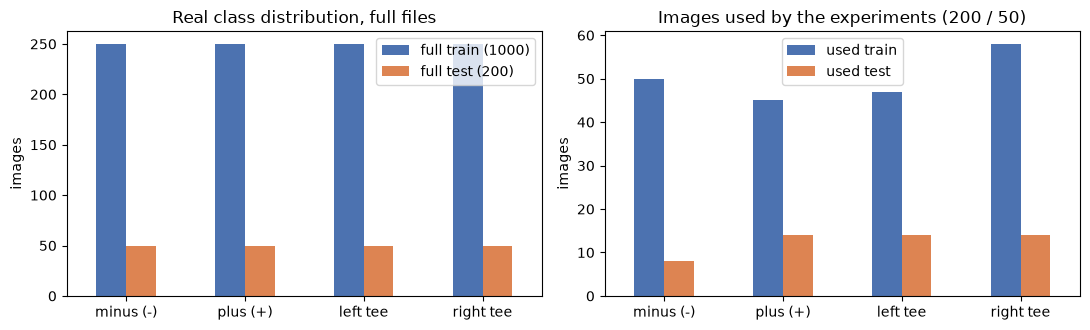

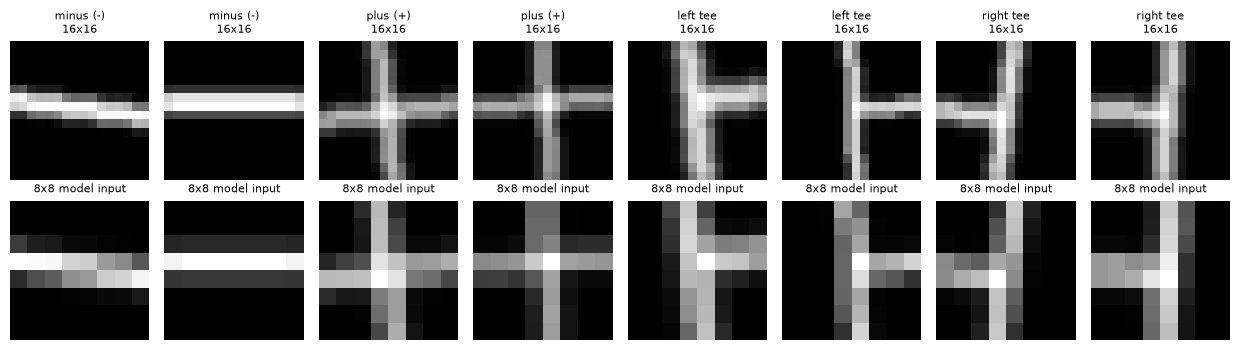

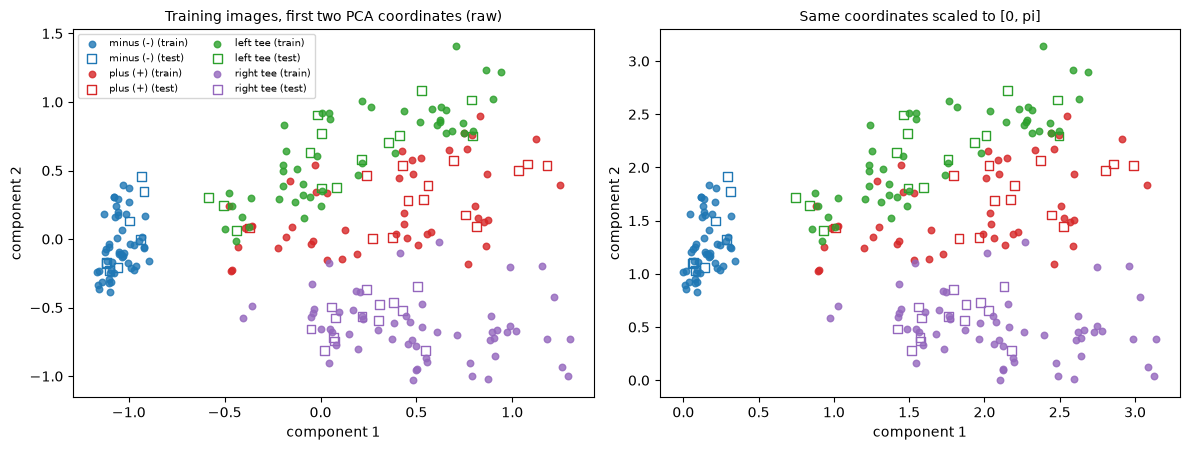

PCA explained variance (2 components): 47.3 %
Note: the model does not use these 2-D angles. It multiplies each of the 64 pixels in [0, 1] by a trainable weight (initialised in [0, 0.1] rad) and adds a bias; the [0, pi] panel only shows how the classes would sit in an angle range.


In [5]:
CLASS_NAMES = {0: "minus (-)", 1: "plus (+)", 2: "left tee", 3: "right tee"}   # dataset doc: '-', '+', '|-', '-|'
CLASS_COLORS = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]
FEATURE_NAMES = [f"pixel_r{r}_c{c}" for r in range(IMG_SIDE) for c in range(IMG_SIDE)]

print("full file    : train", raw_train.shape, "test", raw_test.shape, "(images, 16, 16), values in [0, 1]")
print("model input  : train", tuple(Xtr.shape), "test", tuple(Xte.shape), "= 64 down-sampled pixels per image")
print("feature names:", FEATURE_NAMES[:4], "...", FEATURE_NAMES[-2:], f"({len(FEATURE_NAMES)} features)")
print("original label values:", sorted(np.unique(lab_train).tolist()), "->", CLASS_NAMES)
cnt = pd.DataFrame({"full train (1000)": np.bincount(lab_train, minlength=4), "used train": np.bincount(ytr.numpy(), minlength=4),
                    "full test (200)": np.bincount(lab_test, minlength=4), "used test": np.bincount(yte.numpy(), minlength=4)},
                   index=[CLASS_NAMES[i] for i in range(4)])
display(cnt)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
cnt[["full train (1000)", "full test (200)"]].plot.bar(ax=ax[0], rot=0, color=["#4c72b0", "#dd8452"]); ax[0].set_title("Real class distribution, full files")
cnt[["used train", "used test"]].plot.bar(ax=ax[1], rot=0, color=["#4c72b0", "#dd8452"]); ax[1].set_title("Images used by the experiments (200 / 50)")
for a in ax: a.set_ylabel("images")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(12.5, 3.6))
for k in range(4):
    idx = np.where(lab_train == k)[0][:2]
    for j, i in enumerate(idx):
        axes[0, 2 * k + j].imshow(raw_train[i], cmap="gray"); axes[0, 2 * k + j].set_title(f"{CLASS_NAMES[k]}\n16x16", fontsize=8)
        axes[1, 2 * k + j].imshow(X_train_all[i].reshape(8, 8), cmap="gray"); axes[1, 2 * k + j].set_title("8x8 model input", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

# 2-D scatter of the real images: PCA fitted on the 200 training images only
pca = PCA(n_components=2, random_state=SEED).fit(Xtr.numpy())
P_tr, P_te = pca.transform(Xtr.numpy()), pca.transform(Xte.numpy())
mm = MinMaxScaler((0, np.pi)).fit(P_tr)
A_tr, A_te = mm.transform(P_tr), np.clip(mm.transform(P_te), 0, np.pi)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, (Ptr_, Pte_), ttl in zip(ax, [(P_tr, P_te), (A_tr, A_te)],
                                ["Training images, first two PCA coordinates (raw)", "Same coordinates scaled to [0, pi]"]):
    for k in range(4):
        m = ytr.numpy() == k; a.scatter(Ptr_[m, 0], Ptr_[m, 1], s=22, c=CLASS_COLORS[k], label=f"{CLASS_NAMES[k]} (train)", alpha=.8)
        m = yte.numpy() == k; a.scatter(Pte_[m, 0], Pte_[m, 1], s=40, facecolors="none", edgecolors=CLASS_COLORS[k], marker="s", label=f"{CLASS_NAMES[k]} (test)")
    a.set_title(ttl, fontsize=10); a.set_xlabel("component 1"); a.set_ylabel("component 2")
ax[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()
print("PCA explained variance (2 components): %.1f %%" % (100 * pca.explained_variance_ratio_.sum()))
print("Note: the model does not use these 2-D angles. It multiplies each of the 64 pixels in [0, 1] by a trainable weight "
      "(initialised in [0, 0.1] rad) and adds a bias; the [0, pi] panel only shows how the classes would sit in an angle range.")

## 2. The QNN and three ways of running it

The classifier is the authors' `QML_classifier`: the angles of all `Rot` gates of a `StronglyEntanglingLayers` circuit are
`weights * x_tiled + bias`, with `x_tiled` the 64 pixels repeated three times and reshaped to `(16, 4, 3)`. The prediction is the
`argmax` of the four `<Z_i>`. The same circuit is needed in three forms:

1. **PennyLane QNode** on `default.qubit` (exact, noise-free). This is the object the paper builds; it is used for the circuit
   drawing and as the reference for the equivalence checks below.
2. **Qiskit circuit** (`rz, ry, rz` for each `Rot`, a CNOT ring per layer, measurement of the four qubits). This is what Aer
   runs, after `transpile` to the native gates and connectivity of the fake backend. Only the four measured qubits are simulated
   (as a 4-qubit density matrix), which is what makes one circuit take about 0.05 s instead of the several seconds the authors report.
3. **A batched PyTorch density-matrix simulator** (`NoisyDensitySim`) of the same circuit, differentiable and about 1000x faster than
   parameter-shift on Aer. After every layer each wire passes through a single-qubit noise channel (amplitude damping, phase damping,
   depolarising) whose strengths are *fitted to the Aer fake backend* in Section 5. This replaces the authors'
   2.6-day-per-run parameter-shift training; it is the main CHOICE of this notebook, and Sections 5 and 9 measure how faithful it is.

The cell below defines all three and then asserts that they agree.

In [6]:
# ------------------------------------------------------------------ circuit definition (single source of truth)
def sel_ranges(n_layers, n_wires):
    """Entangling ranges of qml.StronglyEntanglingLayers when ranges=None: r_l = (l mod (n_wires-1)) + 1."""
    return [(l % (n_wires - 1)) + 1 for l in range(n_layers)]

def gate_list(n_layers=N_LAYERS, n_wires=N_QUBITS):
    """('rot', wire, layer) and ('cnot', control, target) in execution order."""
    gl = []
    for l, r in enumerate(sel_ranges(n_layers, n_wires)):
        gl += [("rot", i, l) for i in range(n_wires)]
        gl += [("cnot", i, (i + r) % n_wires) for i in range(n_wires)]
    return gl

def rot_matrix(phi, theta, omega):
    """qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi), batched; returns (..., 2, 2) complex."""
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    e = lambda a: torch.complex(torch.cos(a), torch.sin(a))
    m = [[e(-(phi + omega) / 2) * c, -e((phi - omega) / 2) * s], [e(-(phi - omega) / 2) * s, e((phi + omega) / 2) * c]]
    return torch.stack([torch.stack(r, -1) for r in m], -2)

def _bit(f, w, n):
    return (f >> (n - 1 - w)) & 1

class NoisyDensitySim(torch.nn.Module):
    """Differentiable batched density-matrix simulator of the StronglyEntanglingLayers circuit (wire 0 = most significant bit).
    After every layer (Rot on all wires, then the CNOT ring) each wire passes through the channel
    depolarising(p) o phase-damping(lam) o amplitude-damping(gamma), then an affine read-out map a*<Z>+b per wire."""
    def __init__(self, n=N_QUBITS, n_layers=N_LAYERS, noisy=True):
        super().__init__()
        self.n, self.L, self.noisy = n, n_layers, noisy
        D = 2 ** n; idx = torch.arange(D)
        self.cnot_inv = []                       # inverse basis-state permutation of the CNOT ring of each layer
        for r in sel_ranges(n_layers, n):
            f = idx.clone()
            for i in range(n):
                f = torch.where(_bit(f, i, n) == 1, f ^ (1 << (n - 1 - (i + r) % n)), f)
            self.cnot_inv.append(torch.argsort(f))
        self.signs = torch.stack([1.0 - 2.0 * _bit(idx, w, n).to(torch.float64) for w in range(n)], 1)
        self.raw = torch.nn.Parameter(torch.full((n, 3), -5.0, dtype=torch.float64), requires_grad=False)   # [p, lam, gamma] before 0.5*sigmoid
        self.ro_a = torch.nn.Parameter(torch.ones(n, dtype=torch.float64), requires_grad=False)
        self.ro_b = torch.nn.Parameter(torch.zeros(n, dtype=torch.float64), requires_grad=False)

    def channel_params(self):
        return 0.5 * torch.sigmoid(self.raw)

    def superops(self):
        P = self.channel_params(); mats = []
        z, o = torch.zeros((), dtype=torch.float64), torch.ones((), dtype=torch.float64)
        for w in range(self.n):
            p, lam, g = P[w, 0], P[w, 1], P[w, 2]; s = torch.sqrt(1 - g); q = 2 * p / 3
            AD = torch.stack([torch.stack(r) for r in [[o, z, z, g], [z, s, z, z], [z, z, s, z], [z, z, z, 1 - g]]])
            PH = torch.diag(torch.stack([o, 1 - lam, 1 - lam, o]))
            DP = torch.stack([torch.stack(r) for r in [[1 - q, z, z, q], [z, 1 - 4 * p / 3, z, z], [z, z, 1 - 4 * p / 3, z], [q, z, z, 1 - q]]])
            mats.append(DP @ PH @ AD)                      # acts on (rho00, rho01, rho10, rho11) of one wire
        return mats

    def _apply_channel(self, rho, mats):
        n, B = self.n, rho.shape[0]
        r = rho.reshape((B,) + (2,) * (2 * n))
        for w in range(n):
            r = torch.movedim(r, (1 + w, 1 + n + w), (-2, -1)); sh = r.shape
            r = (r.reshape(*sh[:-2], 4) @ mats[w].T.to(torch.complex128)).reshape(sh)
            r = torch.movedim(r, (-2, -1), (1 + w, 1 + n + w))
        return r.reshape(B, 2 ** n, 2 ** n)

    def expvals(self, theta):
        """theta (B, L, n, 3) rotation angles -> (B, n) expectation values <Z_i> (after the read-out map)."""
        n, B, D = self.n, theta.shape[0], 2 ** self.n
        mats = self.superops() if self.noisy else None
        rho = torch.zeros((B, D, D), dtype=torch.complex128); rho[:, 0, 0] = 1.0
        for l in range(self.L):
            Us = [rot_matrix(theta[:, l, w, 0], theta[:, l, w, 1], theta[:, l, w, 2]) for w in range(n)]
            U = Us[0]
            for w in range(1, n):
                U = torch.einsum("zab,zcd->zacbd", U, Us[w]).reshape(B, U.shape[1] * 2, U.shape[2] * 2)
            rho = U @ rho @ U.conj().transpose(1, 2)
            finv = self.cnot_inv[l]; rho = rho[:, finv][:, :, finv]
            if self.noisy:
                rho = self._apply_channel(rho, mats)
        z = torch.diagonal(rho, dim1=1, dim2=2).real @ self.signs
        return self.ro_a * z + self.ro_b

# ------------------------------------------------------------------ the model of the paper
def make_theta(w, b, x, tanh=False):
    """angles = weights * tiled(x) + bias, shape (B, L, n, 3); tanh=True is the 'non-linear feature map' defence."""
    xx = torch.tanh(x) if tanh else x
    return w * torch.cat([xx] * N_REUP, dim=1).reshape(len(x), N_LAYERS, N_QUBITS, 3) + b

class QNN(torch.nn.Module):
    """Authors' QML_classifier: weights and bias of shape (16, 4, 3) initialised 0.1*rand with torch.manual_seed(seed)."""
    def __init__(self, sim, tanh=False, seed=PAPER_SEED):
        super().__init__()
        torch.manual_seed(seed)
        self.sim, self.tanh = [sim], tanh            # list: the simulator is shared and not a sub-module of the model
        self.weights = torch.nn.Parameter(0.1 * torch.rand(N_LAYERS, N_QUBITS, 3, dtype=torch.float64))
        self.bias = torch.nn.Parameter(0.1 * torch.rand(N_LAYERS, N_QUBITS, 3, dtype=torch.float64))
    def theta(self, x):
        return make_theta(self.weights, self.bias, x, self.tanh)
    def forward(self, x):
        return self.sim[0].expvals(self.theta(x))

# ------------------------------------------------------------------ Qiskit circuit + fake backend wrapper
def logical_circuit(n=N_QUBITS, n_layers=N_LAYERS, measure=True):
    """Same gate list as gate_list(): per Rot an rz-ry-rz triple, then the CNOT ring; parameter k = (layer*n + wire)*3 + {0,1,2}."""
    pv = ParameterVector("t", n_layers * n * 3)
    qc = QuantumCircuit(n, n if measure else 0)
    for l, r in enumerate(sel_ranges(n_layers, n)):
        for i in range(n):
            a, b, c = [pv[(l * n + i) * 3 + k] for k in range(3)]
            qc.rz(a, i); qc.ry(b, i); qc.rz(c, i)
        for i in range(n):
            qc.cx(i, (i + r) % n)
    if measure:
        qc.measure(range(n), range(n))
    return qc, pv

class FakeDevice:
    """Runs the QNN circuit on Aer with the noise model of a fake backend (density-matrix method, only the 4 used qubits)."""
    def __init__(self, backend, seed=SEED, shots=SHOTS):
        self.backend, self.shots, self.seed = backend, shots, seed
        self.qc, self.pv = logical_circuit()
        self.tq = transpile(self.qc, backend, optimization_level=1, seed_transpiler=seed)     # transpiled once; angles are bound per sample
        self.sim = AerSimulator.from_backend(backend, method="density_matrix", max_parallel_threads=1)
        self.active = sorted({self.tq.find_bit(q).index for ins in self.tq.data for q in ins.qubits})
    def expvals(self, theta, shots=None):
        shots = shots or self.shots
        th = theta.detach().cpu().numpy().reshape(len(theta), -1)
        circs = [self.tq.assign_parameters(dict(zip(self.pv, t))) for t in th]
        res = self.sim.run(circs, shots=shots, seed_simulator=self.seed).result()
        z = np.zeros((len(th), N_QUBITS))
        for k in range(len(th)):
            for key, c in res.get_counts(k).items():
                bits = key[::-1]                                  # classical bit i = qubit i is the i-th character from the right
                for i in range(N_QUBITS):
                    z[k, i] += (1 if bits[i] == "0" else -1) * c / shots
        return torch.tensor(z)
print("definitions ready")

definitions ready

In [7]:
# ---------- equivalence checks: PennyLane QNode == batched simulator == Qiskit circuit; noisy simulator == PennyLane default.mixed ----------
pl_dev = qml.device("default.qubit", wires=N_QUBITS)
@qml.qnode(pl_dev, interface="torch")
def pl_qnode(inputs, weights, bias):                 # the authors' circuit (their `circuit(inputs, weights, bias)`)
    qml.StronglyEntanglingLayers(weights=weights * inputs + bias, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

g = torch.Generator().manual_seed(SEED)
th = (torch.rand(3, N_LAYERS, N_QUBITS, 3, dtype=torch.float64, generator=g) * 2 * math.pi)
ref = torch.stack([torch.stack(pl_qnode(torch.ones(N_LAYERS, N_QUBITS, 3, dtype=torch.float64), t, torch.zeros(N_LAYERS, N_QUBITS, 3, dtype=torch.float64))) for t in th])
mine = NoisyDensitySim(noisy=False).expvals(th)
d1 = (ref - mine).abs().max().item()
qc_nm, pv_nm = logical_circuit(measure=False)
ops = [SparsePauliOp("I" * (N_QUBITS - 1 - i) + "Z" + "I" * i) for i in range(N_QUBITS)]    # Qiskit labels are little-endian: qubit i = i-th from the right
qk = torch.tensor([[Statevector(qc_nm.assign_parameters(dict(zip(pv_nm, t.reshape(-1).numpy())))).expectation_value(o).real for o in ops] for t in th])
d2 = (qk - ref).abs().max().item()
print("noise-free: |PennyLane QNode - batched simulator| = %.1e,  |Qiskit statevector - PennyLane QNode| = %.1e" % (d1, d2))
assert d1 < 1e-10 and d2 < 1e-10

# noisy simulator against PennyLane's own density-matrix device with the same channels
sim_t = NoisyDensitySim(); vals = np.array([[0.01, 0.02, 0.03], [0.005, 0.01, 0.05], [0.02, 0.0, 0.02], [0.0, 0.03, 0.04]])
sim_t.raw.data = torch.logit(torch.tensor(vals) * 2); sim_t.ro_a.data = torch.tensor([.97, .95, .98, .96], dtype=torch.float64); sim_t.ro_b.data = torch.tensor([.01, -.01, 0., .02], dtype=torch.float64)
@qml.qnode(qml.device("default.mixed", wires=N_QUBITS), interface="torch")
def pl_noisy(t):
    for l, r in enumerate(sel_ranges(N_LAYERS, N_QUBITS)):
        for a in range(N_QUBITS): qml.Rot(t[l, a, 0], t[l, a, 1], t[l, a, 2], wires=a)
        for a in range(N_QUBITS): qml.CNOT(wires=[a, (a + r) % N_QUBITS])
        for a in range(N_QUBITS):
            p, lam, gam = vals[a]
            qml.AmplitudeDamping(float(gam), wires=a); qml.PhaseDamping(float(1 - (1 - lam) ** 2), wires=a); qml.DepolarizingChannel(float(p), wires=a)
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
ref_n = torch.stack(pl_noisy(th[0])) * sim_t.ro_a + sim_t.ro_b
d3 = (ref_n - sim_t.expvals(th[:1])[0]).abs().max().item()
print("noisy: |PennyLane default.mixed - batched noisy simulator| = %.1e" % d3)
assert d3 < 1e-9
print("all equivalence checks passed")

noise-free: |PennyLane QNode - batched simulator| = 5.6e-16,  |Qiskit statevector - PennyLane QNode| = 1.1e-15


noisy: |PennyLane default.mixed - batched noisy simulator| = 2.2e-13
all equivalence checks passed


## Quantum Circuit Architecture

**Circuit that is executed.** One architecture is trained and evaluated everywhere in Sections 5-8: **4 qubits, 16
`StronglyEntanglingLayers` layers**, each layer a `Rot(phi, theta, omega)` on every qubit followed by a ring of four CNOTs whose
range cycles through 1, 2, 3 (`r_l = (l mod 3) + 1`). The 64 pixels are tiled three times (`r = 3`) into the 192 rotation angles
`weights * x + bias` ("data re-uploading" in the paper's wording; there is no separate encoding layer, the data enters the
rotation angles of every layer). The model has 192 weights + 192 biases = **384 trainable parameters**. The output is the
Pauli-Z expectation on every qubit; the four values are the class logits. The performance benchmark of Section 8 additionally times an
8-qubit, 32-layer version of the same template (drawn there).

Assumptions where the paper is silent: the CNOT ranges of `StronglyEntanglingLayers` are the library default (not stated in the
paper); the circuit that reaches Aer is the transpilation of the Qiskit form for each backend (optimisation level 1, seed 42), whose
qubit placement and routing the paper does not describe.

The figures below show (1) the PennyLane QNode, (2) a zoom on its first two layers, (3) the noisy two-layer variant used for the
equivalence check (the same channels as the surrogate), (4) the Qiskit circuit that Aer receives and (5) its transpilation for
`FakeGuadalupeV2`.

PennyLane QNode: qubits =

 4 | depth = 65 | gates = {'Rot': 64, 'CNOT': 64} | trainable parameters = weights 192 + bias 192 = 384


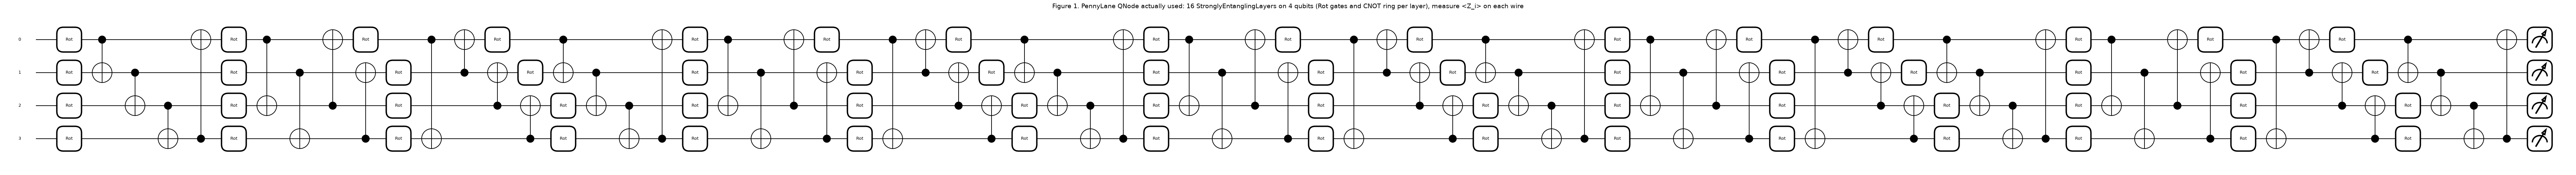

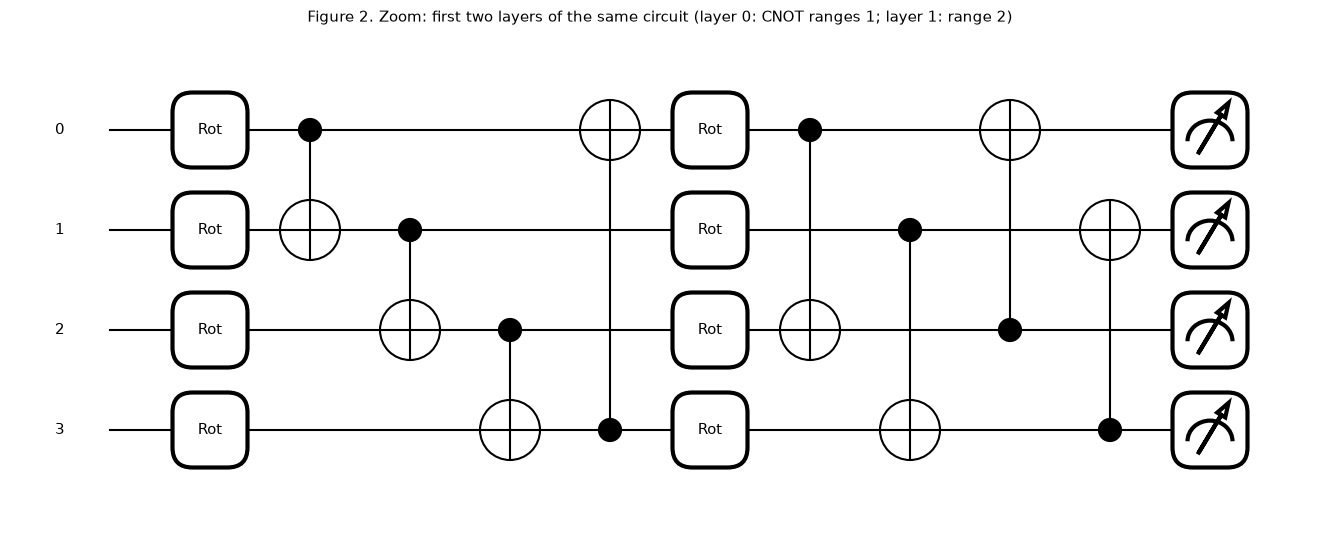

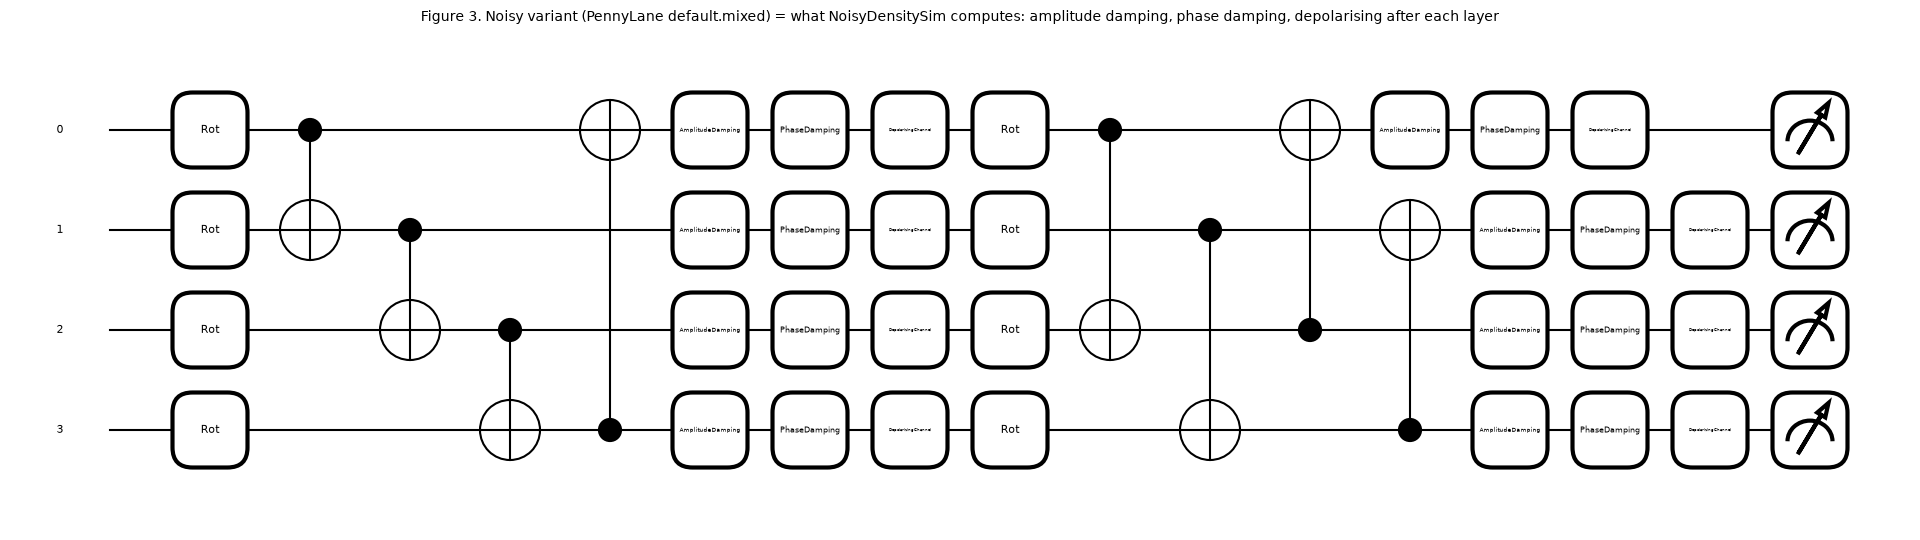

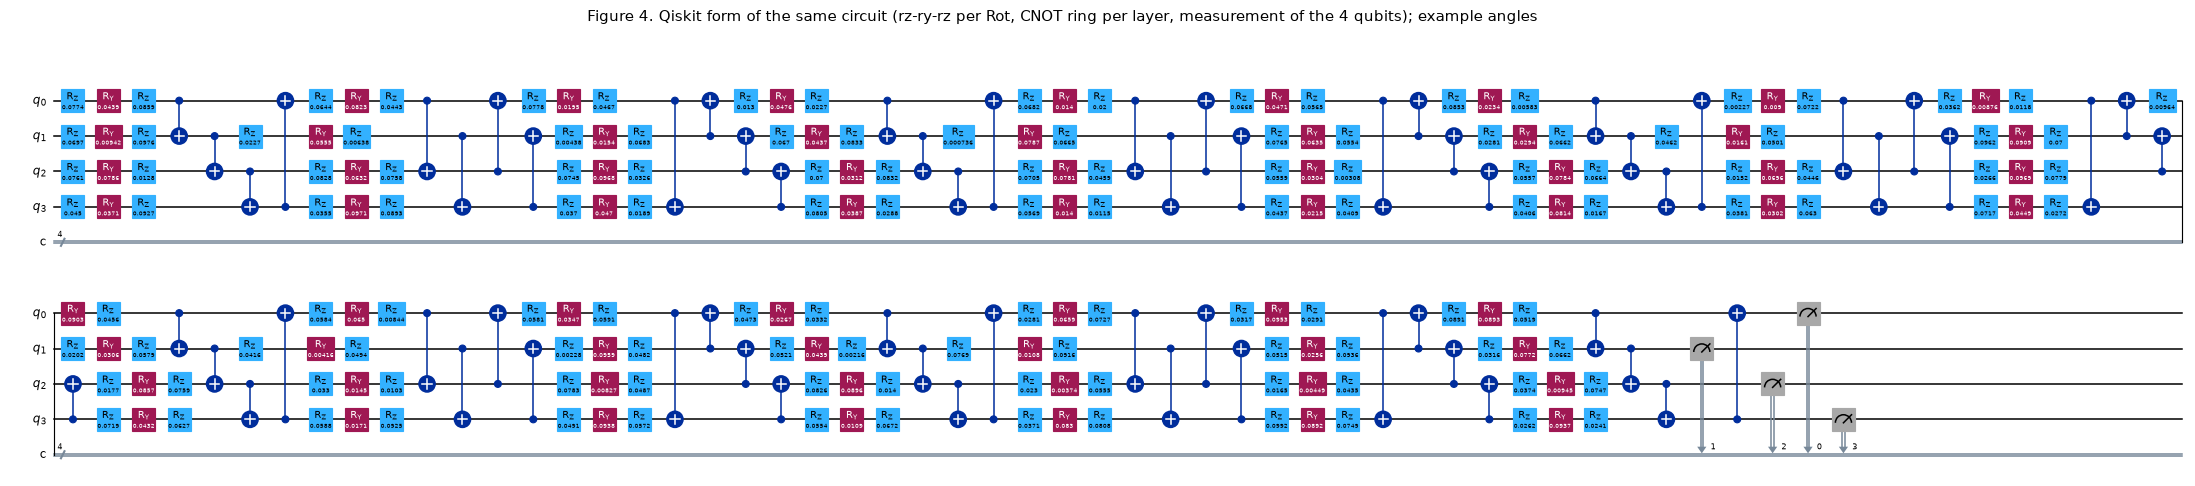

Qiskit logical circuit: qubits = 4 | depth = 98 | ops = {'rz': 128, 'ry': 64, 'cx': 64, 'measure': 4} | parameters = 192


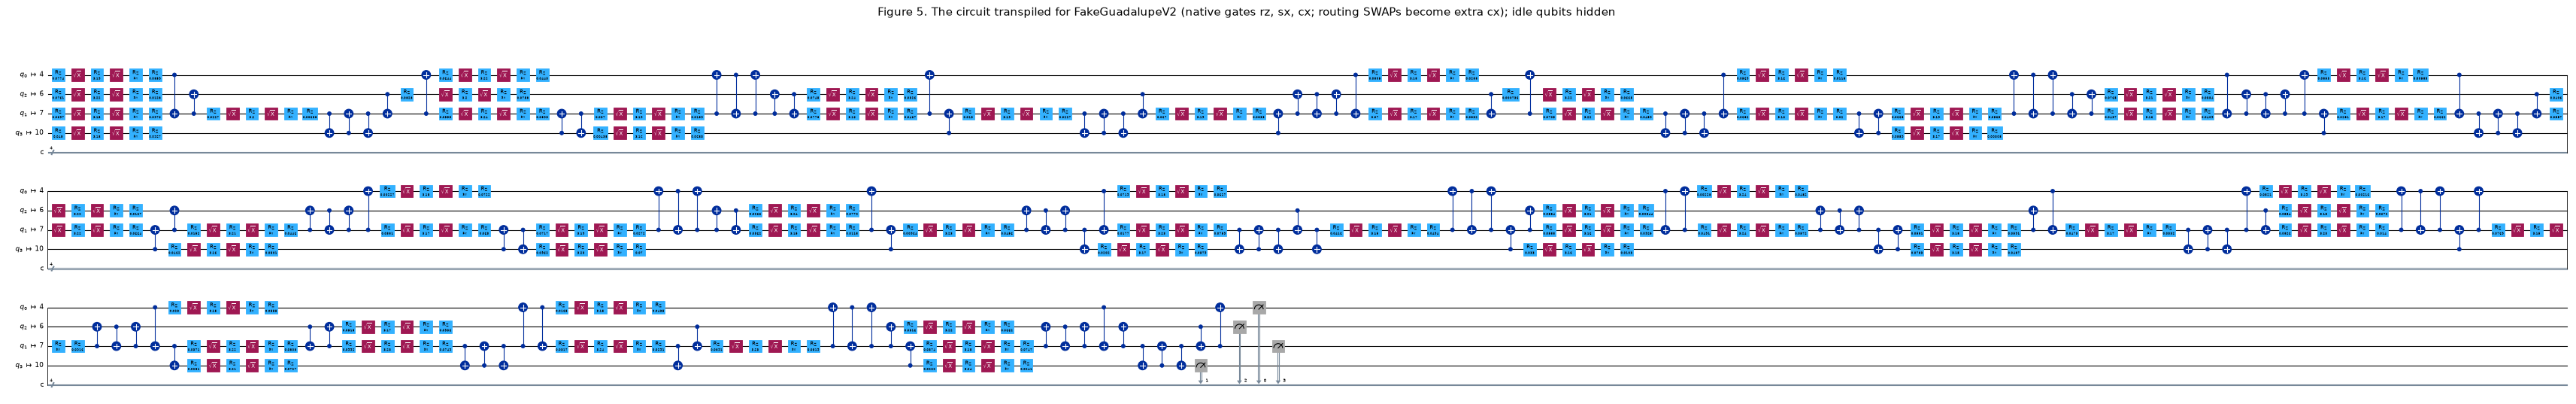

,backend,device_qubits,physical_qubits_used,depth,cx,sx,rz
0,FakeGuadalupeV2,16,"[4, 6, 7, 10]",320,127,128,256
1,FakeLimaV2,5,"[0, 1, 2, 3]",320,127,128,256
2,FakeJakartaV2,7,"[0, 1, 2, 3]",324,125,128,256


Logical CNOTs in the QNN: 64; the transpiled circuits need about twice as many cx because the 4-qubit ring does not fit the device connectivity.


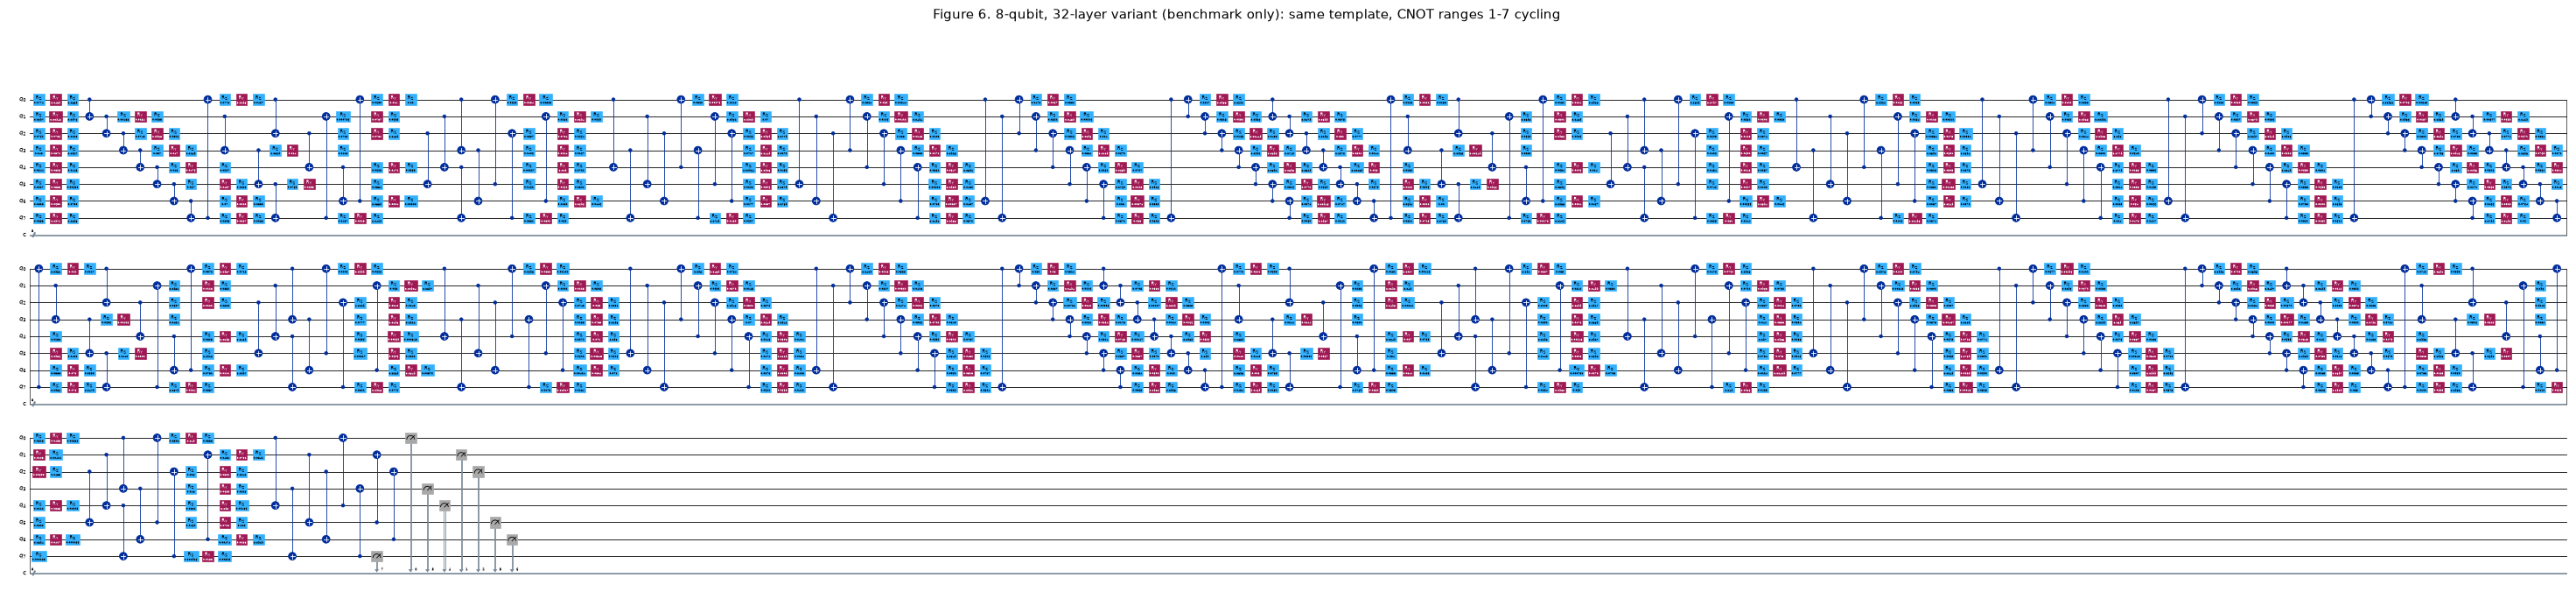

8-qubit variant: qubits = 8 | depth = 222 | ops = {'rz': 512, 'ry': 256, 'cx': 256, 'measure': 8} | angle parameters = 768 (weights + bias = 1536 trainable)


In [8]:
inp0 = torch.rand(N_LAYERS, N_QUBITS, 3, dtype=torch.float64); w0 = 0.1 * torch.rand(N_LAYERS, N_QUBITS, 3, dtype=torch.float64); b0 = 0.1 * torch.rand(N_LAYERS, N_QUBITS, 3, dtype=torch.float64)
specs = qml.specs(pl_qnode, level="device")(inp0, w0, b0)
res = specs.resources
print("PennyLane QNode: qubits =", getattr(res, "num_allocs", N_QUBITS), "| depth =", res.depth, "| gates =", dict(res.gate_types), "| trainable parameters = weights %d + bias %d = %d"
      % (w0.numel(), b0.numel(), w0.numel() + b0.numel()))
fig, ax = qml.draw_mpl(pl_qnode, level="device", decimals=None, fontsize=9)(inp0, w0, b0)
fig.suptitle("Figure 1. PennyLane QNode actually used: 16 StronglyEntanglingLayers on 4 qubits (Rot gates and CNOT ring per layer), measure <Z_i> on each wire", y=1.02, fontsize=14)
plt.show()

# zoom on the first two layers (same template, n_layers=2)
@qml.qnode(qml.device("default.qubit", wires=N_QUBITS), interface="torch")
def pl_two_layers(inputs, weights, bias):
    qml.StronglyEntanglingLayers(weights=weights * inputs + bias, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
fig, ax = qml.draw_mpl(pl_two_layers, level="device", decimals=None, fontsize=11)(inp0[:2], w0[:2], b0[:2])
fig.suptitle("Figure 2. Zoom: first two layers of the same circuit (layer 0: CNOT ranges 1; layer 1: range 2)", y=1.04, fontsize=11)
plt.show()

# noisy two-layer circuit of the equivalence check: rotations, CNOT ring, then the three noise channels on every wire
@qml.qnode(qml.device("default.mixed", wires=N_QUBITS), interface="torch")
def pl_noisy_two(t):
    for l, r in enumerate(sel_ranges(2, N_QUBITS)):
        for a in range(N_QUBITS): qml.Rot(t[l, a, 0], t[l, a, 1], t[l, a, 2], wires=a)
        for a in range(N_QUBITS): qml.CNOT(wires=[a, (a + r) % N_QUBITS])
        for a in range(N_QUBITS):
            qml.AmplitudeDamping(0.02, wires=a); qml.PhaseDamping(0.01, wires=a); qml.DepolarizingChannel(0.01, wires=a)
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
fig, ax = qml.draw_mpl(pl_noisy_two, decimals=None, fontsize=8)(w0[:2])
fig.suptitle("Figure 3. Noisy variant (PennyLane default.mixed) = what NoisyDensitySim computes: amplitude damping, phase damping, depolarising after each layer", y=1.04, fontsize=10)
plt.show()

# Qiskit circuit that Aer runs (logical form, with example angles), and its transpilation
qc_show, pv_show = logical_circuit()
qc_bound = qc_show.assign_parameters(dict(zip(pv_show, (0.1 * np.random.default_rng(SEED).random(len(pv_show))))))
fig = qc_bound.draw("mpl", fold=60, scale=0.55, idle_wires=False)
fig.suptitle("Figure 4. Qiskit form of the same circuit (rz-ry-rz per Rot, CNOT ring per layer, measurement of the 4 qubits); example angles", y=1.0, fontsize=11)
display(fig)
print("Qiskit logical circuit: qubits =", qc_show.num_qubits, "| depth =", qc_show.depth(), "| ops =", dict(qc_show.count_ops()), "| parameters =", len(pv_show))

DEV_GUAD = FakeDevice(FakeGuadalupeV2())
tq = DEV_GUAD.tq
fig = tq.assign_parameters(dict(zip(DEV_GUAD.pv, (0.1 * np.random.default_rng(SEED).random(len(DEV_GUAD.pv)))))).draw("mpl", fold=130, scale=0.4, idle_wires=False)
fig.suptitle("Figure 5. The circuit transpiled for FakeGuadalupeV2 (native gates rz, sx, cx; routing SWAPs become extra cx); idle qubits hidden", y=1.0, fontsize=11)
display(fig)
tab = []
for name, cls in FAKE_BACKENDS.items():
    d = DEV_GUAD if name == "FakeGuadalupeV2" else FakeDevice(cls())
    tab.append(dict(backend=name, device_qubits=d.backend.num_qubits, physical_qubits_used=str(d.active), depth=d.tq.depth(),
                    cx=d.tq.count_ops().get("cx", 0), sx=d.tq.count_ops().get("sx", 0), rz=d.tq.count_ops().get("rz", 0)))
display(pd.DataFrame(tab))
print("Logical CNOTs in the QNN: %d; the transpiled circuits need about twice as many cx because the 4-qubit ring does not fit the device connectivity." % sum(k == "cnot" for k, _, _ in gate_list()))
# the 8-qubit, 32-layer variant of the authors' 8-qubit script: only timed in Section 10 (not trained), drawn here for completeness
qc8, pv8 = logical_circuit(8, 32)
fig = qc8.assign_parameters(dict(zip(pv8, 0.1 * np.random.default_rng(SEED).random(len(pv8))))).draw("mpl", fold=150, scale=0.3)
fig.suptitle("Figure 6. 8-qubit, 32-layer variant (benchmark only): same template, CNOT ranges 1-7 cycling", y=1.0, fontsize=11)
display(fig)
print("8-qubit variant: qubits =", qc8.num_qubits, "| depth =", qc8.depth(), "| ops =", dict(qc8.count_ops()), "| angle parameters =", len(pv8), "(weights + bias = %d trainable)" % (2 * len(pv8)))

## 3. Fitting the fast noisy model to the Aer fake backend

The authors differentiate the noisy circuit with parameter-shift rules on Aer: every gradient needs 2 x 192 circuit runs per sample, which
is why one 4-qubit run took 2.6 days on their machine. Here the white-box gradients come from `NoisyDensitySim`, whose
per-wire channels (depolarising `p`, phase damping `lam`, amplitude damping `gamma`) and read-out map `a*<Z>+b` are fitted by gradient
descent to the expectation values that Aer returns for the same circuits on the fake backend. The calibration circuits use random
angles at four magnitudes (so that the fit covers circuits close to the identity, as at initialisation, and strongly rotated
ones) and real training images; **no labels and no test images are used**. The cell prints the root-mean-square error on held-out
random circuits next to the shot-noise floor of Aer (about `1/sqrt(1024) = 0.03`): a fit at the floor cannot be improved with this data.

calibrating FakeGuadalupeV2


    step   0  rmse(fit set) = 0.1831


    step  30  rmse(fit set) = 0.0320


    step  59  rmse(fit set) = 0.0259


calibrating FakeLimaV2


...

calibrating FakeJakartaV2


    step   0  rmse(fit set) = 0.2756


    step  30  rmse(fit set) = 0.0711


    step  59  rmse(fit set) = 0.0361


,backend,rmse_fit,rmse_heldout,shot_noise_floor,mean_depolarising,mean_phase_damping,mean_amp_damping,readout_scale,seconds
0,FakeGuadalupeV2,0.0259,0.0274,0.0264,0.0106,0.0150,0.0153,0.9898,74.5360
1,FakeLimaV2,0.0258,0.0285,0.0259,0.0095,0.0054,0.0125,0.9798,52.7256
2,FakeJakartaV2,0.0361,0.0451,0.0242,0.0077,0.0075,0.0110,1.0000,48.2525


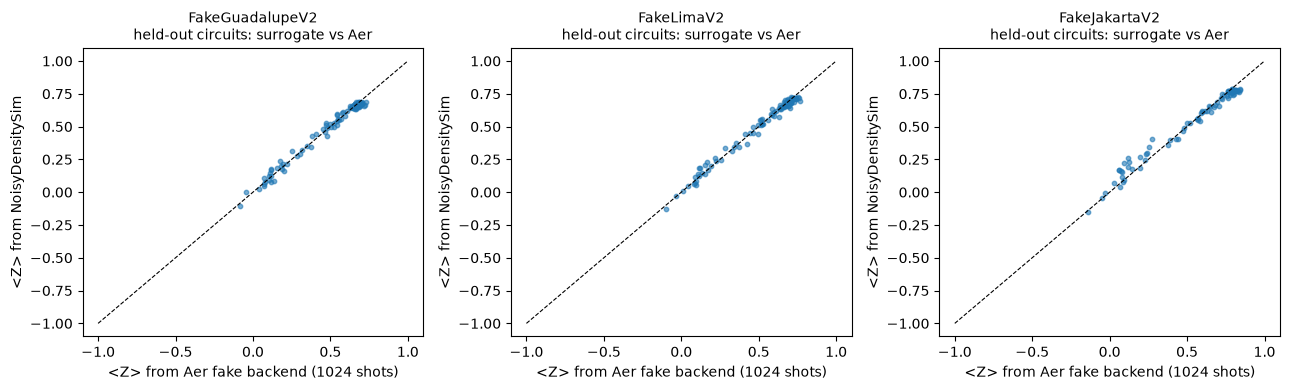

In [9]:
def random_circuits(X, n, seed):
    g = torch.Generator().manual_seed(seed); scales = [0.1, 0.3, 1.0, 3.0]; m = n // len(scales); out = []
    for sc in scales:
        shp = (N_LAYERS, N_QUBITS, 3)
        w = sc * torch.rand(shp, dtype=torch.float64, generator=g) if sc == 0.1 else sc * (2 * torch.rand(shp, dtype=torch.float64, generator=g) - 1)
        b = 0.1 * sc * torch.rand(shp, dtype=torch.float64, generator=g)
        out.append(make_theta(w, b, X[torch.randint(0, len(X), (m,), generator=g)]))
    return torch.cat(out)

def calibrate(dev, sim, X, n_cal, steps, verbose=True):
    theta, theta_ho = random_circuits(X, n_cal, SEED), random_circuits(X, 24, SEED + 1)
    za, za_ho = dev.expvals(theta), dev.expvals(theta_ho)
    sim.raw.data.fill_(-3.0); sim.ro_a.data.fill_(1.0); sim.ro_b.data.zero_()
    params = [sim.raw, sim.ro_a, sim.ro_b]
    for p in params: p.requires_grad_(True)
    opt = torch.optim.Adam(params, lr=0.05)
    for s in range(steps):
        loss = ((sim.expvals(theta) - za) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sim.ro_a.data.clamp_(0.7, 1.0)      # read-out can only shrink the signal
        if verbose and (s % 30 == 0 or s == steps - 1):
            print(f"    step {s:3d}  rmse(fit set) = {loss.sqrt().item():.4f}")
    for p in params: p.requires_grad_(False)
    with torch.no_grad():
        zs_ho = sim.expvals(theta_ho)
    floor = float(torch.sqrt(((1 - za_ho ** 2) / SHOTS).mean()))
    return dict(rmse_fit=float(loss.sqrt()), rmse_heldout=float(((zs_ho - za_ho) ** 2).mean().sqrt()), shot_noise_floor=floor, zs_ho=zs_ho, za_ho=za_ho)

CTX = {}
rows = []
for name in BACKENDS:
    t0 = time.time(); print("calibrating", name)
    dev = DEV_GUAD if name == "FakeGuadalupeV2" else FakeDevice(FAKE_BACKENDS[name]())
    sim = NoisyDensitySim()
    cal = calibrate(dev, sim, Xtr, N_CAL, CAL_STEPS)
    CTX[name] = dict(dev=dev, sim=sim, cal=cal)
    P = sim.channel_params().detach().numpy()
    rows.append(dict(backend=name, rmse_fit=cal["rmse_fit"], rmse_heldout=cal["rmse_heldout"], shot_noise_floor=cal["shot_noise_floor"],
                     mean_depolarising=P[:, 0].mean(), mean_phase_damping=P[:, 1].mean(), mean_amp_damping=P[:, 2].mean(),
                     readout_scale=float(sim.ro_a.mean()), seconds=time.time() - t0))
CTX["NoiseFree"] = dict(dev=None, sim=NoisyDensitySim(noisy=False), cal=None)      # exact, no noise, no shots (the paper's default.mixed control)
display(pd.DataFrame(rows).round(4))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, name in zip(ax, BACKENDS):
    c = CTX[name]["cal"]; a.scatter(c["za_ho"].numpy().ravel(), c["zs_ho"].numpy().ravel(), s=10, alpha=.6)
    a.plot([-1, 1], [-1, 1], "k--", lw=.8); a.set_title(f"{name}\nheld-out circuits: surrogate vs Aer", fontsize=10)
    a.set_xlabel("<Z> from Aer fake backend (1024 shots)"); a.set_ylabel("<Z> from NoisyDensitySim")
plt.tight_layout(); plt.show()

## 4. Training, the PGD attack and the defences

All functions follow the authors' scripts (`PGD_Attack_Reduced_Noise_Fake_Guadalupe_4qubits*.py` at the pinned commit).

* **Training**: Adam (lr 0.1), cross-entropy on the four `<Z_i>`, 4 epochs of 10 random batches of 20, weights/bias initialised `0.1*rand` with the seed.
* **PGD** (no random start): `delta <- clip(delta + 0.01 * sign(grad_x CE), -0.1, 0.1)` for 10 steps; the perturbed image is `x + delta` and is not clipped to [0, 1].
* **Defences**: `tanh` on the inputs; the Lipschitz penalty (`lip_repo` = what the code does: `0.05 * ||grad_x batch-loss||_2`; `lip_eq3` = Eq. 3 of the paper: `0.05 * mean_k ||grad_x sum_i f_i(x_k)||_2^2`); `StepLR(3, 0.1)` for 8 epochs; adversarial retraining for 2 epochs with the same Adam state, in three variants:
  * `repo10`: 20 PGD examples are *appended* to the 200 training images, but the batch permutation is drawn over `num_train = 200` only, so they are never sampled (this is what the authors' code runs; we reproduce it and flag it);
  * `text10`: what the paper's text says, 20 of the 200 training images *replaced* by their PGD versions;
  * `ratio50`: the 200 PGD examples added to the 200 clean images (400 samples).
* **Accuracies** are measured on the 50 test images on **Aer with the fake-backend noise** (headline, 1024 shots) and, for comparison, on the surrogate. *Adversarial acc* = accuracy of the clean-trained model on its own PGD examples. *Robust acc (static)* = the retrained model on **the same PGD examples** (the paper's protocol, the examples were made against the model before retraining). *Robust acc (adaptive)* = PGD re-run against the retrained model (our addition).

In [10]:
def gen_batches(n, nb, gen):
    return torch.randperm(n, generator=gen)[: nb * (n // nb)].reshape(nb, -1)

def train(model, X, y, epochs, gen, use_sched=False, lip=None, opt=None, sched=None, n_use=None, Xval=None, yval=None):
    """Mini-batch Adam training as in the authors' loop. n_use: batches are drawn from the first n_use rows only (authors' retraining)."""
    if opt is None:
        opt = torch.optim.Adam(model.parameters(), lr=LR)
    if use_sched and sched is None:
        sched = torch.optim.lr_scheduler.StepLR(opt, step_size=STEPLR_STEP, gamma=STEPLR_GAMMA)
    n = n_use or len(X); nb = n // BATCH; hist = []
    for ep in range(epochs):
        bi = gen_batches(n, nb, gen); tot = 0.0
        for it in range(nb):
            xb = X[bi[it]].clone().requires_grad_(lip is not None); yb = y[bi[it]]
            out = model(xb); loss = F.cross_entropy(out, yb)
            if lip == "repo":          # authors' code: 0.05 * L2 norm of the gradient of the batch loss w.r.t. the whole input batch
                gr = torch.autograd.grad(loss, xb, create_graph=True)[0]; loss = loss + LIP_REG * gr.pow(2).sum().sqrt()
            elif lip == "eq3":         # paper Eq. 3: lambda * mean_k ||grad_x sum_i f_i(x_k)||_2^2
                gr = torch.autograd.grad(out.sum(), xb, create_graph=True)[0]; loss = loss + LIP_REG * gr.pow(2).sum(1).mean()
            opt.zero_grad(); loss.backward(); opt.step(); tot += float(loss)
        if sched is not None:
            sched.step()
        with torch.no_grad():
            va = accuracy(model(Xval), yval) if Xval is not None else float("nan")
        hist.append(dict(epoch=ep + 1, loss=tot / nb, val_acc_surrogate=va, lr=opt.param_groups[0]["lr"]))
    return opt, sched, hist

def pgd(model, X, y, eps=EPS, alpha=ALPHA, iters=PGD_ITERS, chunk=50):
    """White-box L_inf PGD without random start (authors' implementation); returns the perturbation delta."""
    out = []
    for s in range(0, len(X), chunk):
        xb, yb = X[s:s + chunk], y[s:s + chunk]; delta = torch.zeros_like(xb, requires_grad=True)
        for _ in range(iters):
            g, = torch.autograd.grad(F.cross_entropy(model(xb + delta), yb), delta)
            delta = (delta + alpha * g.sign()).clamp(-eps, eps).detach().requires_grad_(True)
        out.append(delta.detach())
    return torch.cat(out)

def accuracy(logits, y):
    return float((logits.argmax(1) == y).double().mean())

def both(ctx, model, X):
    """(surrogate logits, device logits). Device = Aer with the fake-backend noise, or the exact simulator for the noise-free control."""
    with torch.no_grad():
        th = model.theta(X); zs = ctx["sim"].expvals(th)
        return zs, (ctx["dev"].expvals(th) if ctx["dev"] is not None else zs)

def clone_state(model, opt):
    m2 = QNN(model.sim[0], model.tanh, seed=0); m2.load_state_dict(model.state_dict())
    o2 = torch.optim.Adam(m2.parameters(), lr=LR); o2.load_state_dict(copy.deepcopy(opt.state_dict()))
    return m2, o2

STORE = {}      # trained objects kept for the figures (paper seed, Guadalupe / baseline only)

def run_one(bk, strategy, seed, variants=("repo10",), keep=False):
    ctx = CTX[bk]; tanh = strategy == "tanh"; lip = {"lip_repo": "repo", "lip_eq3": "eq3"}.get(strategy); use_sched = strategy == "steplr"
    gen = torch.Generator().manual_seed(seed); t0 = time.time()
    model = QNN(ctx["sim"], tanh=tanh, seed=seed)
    opt, sched, hist = train(model, Xtr, ytr, STEPLR_EPOCHS if use_sched else EPOCHS, gen, use_sched, lip, Xval=Xte, yval=yte)
    t_train = time.time() - t0
    zs_b, za_b = both(ctx, model, Xte)
    delta = pgd(model, Xte, yte)
    zs_a, za_a = both(ctx, model, Xte + delta)
    sgn = (2 * torch.randint(0, 2, Xte.shape, generator=torch.Generator().manual_seed(seed)) - 1).double() * EPS     # random +-eps noise control
    _, za_r = both(ctx, model, Xte + sgn)
    base = dict(backend=bk, strategy=strategy, seed=seed, benign_dev=accuracy(za_b, yte), benign_sur=accuracy(zs_b, yte),
                adv_dev=accuracy(za_a, yte), adv_sur=accuracy(zs_a, yte), random_noise_dev=accuracy(za_r, yte),
                agree_benign=float((zs_b.argmax(1) == za_b.argmax(1)).double().mean()), agree_adv=float((zs_a.argmax(1) == za_a.argmax(1)).double().mean()),
                rmse_sur_dev=float(((zs_b - za_b) ** 2).mean().sqrt()), t_train=t_train)
    adv_pool = pgd(model, Xtr, ytr) if ("text10" in variants or "ratio50" in variants) else None
    out = []
    for v in variants:
        m2, o2 = clone_state(model, opt); g2 = torch.Generator().manual_seed(seed + 1)
        if v == "ratio50":
            Xr, yr, nu = torch.cat([Xtr, Xtr + adv_pool]), torch.cat([ytr, ytr]), 2 * N_TRAIN
        else:
            a20 = (Xtr[:20] + (adv_pool[:20] if adv_pool is not None else pgd(model, Xtr[:20], ytr[:20])))
            if v == "repo10":      # authors' code: appended, but batches are drawn from the first num_train=200 rows only -> never used
                Xr, yr, nu = torch.cat([Xtr, a20]), torch.cat([ytr, ytr[:20]]), N_TRAIN
            else:                  # text10: 20 training images replaced by adversarial versions
                Xr, yr, nu = Xtr.clone(), ytr.clone(), N_TRAIN; Xr[:20] = a20
        _, _, hist2 = train(m2, Xr, yr, RETRAIN_EPOCHS, g2, opt=o2, n_use=nu, Xval=Xte, yval=yte)
        zs_s, za_s = both(ctx, m2, Xte + delta)                       # static: PGD examples made against the model before retraining
        zs_bb, za_bb = both(ctx, m2, Xte)
        d2 = pgd(m2, Xte, yte); zs_d, za_d = both(ctx, m2, Xte + d2)      # adaptive: attack the retrained model
        r = dict(base, variant=v, benign_after_dev=accuracy(za_bb, yte), robust_static_dev=accuracy(za_s, yte), robust_static_sur=accuracy(zs_s, yte),
                 robust_adaptive_dev=accuracy(za_d, yte), robust_adaptive_sur=accuracy(zs_d, yte), final_lr=o2.param_groups[0]["lr"])
        out.append(r)
        if keep:
            STORE[(bk, strategy, seed, v)] = dict(model=m2, za_static=za_s, za_benign=za_bb, hist=hist2)
    if keep:
        STORE[(bk, strategy, seed)] = dict(model=model, delta=delta, za_b=za_b, za_a=za_a, zs_b=zs_b, zs_a=zs_a, hist=hist)
    return out

JOBS = []
for sd in SEEDS:
    for st in STRATEGIES:
        JOBS.append(("FakeGuadalupeV2", st, sd, ("repo10", "text10", "ratio50") if st == "baseline" else ("repo10",)))
    for bk in BACKENDS[1:]:
        JOBS.append((bk, "baseline", sd, ("repo10",)))
    JOBS.append(("NoiseFree", "baseline", sd, ("repo10", "ratio50")))
print(len(JOBS), "jobs")

7 jobs


## 5. Running the experiments

One job = train, attack, retrain, evaluate (on Aer for the three fake backends; exactly for the noise-free control). The paper's seed
(1337) is always run first; its trained objects are kept for the figures of Section 6. The printed lines show
benign / adversarial accuracy of the clean-trained model on the device, and the accuracy after `repo10` retraining against the original
(static) PGD examples.

In [11]:
all_rows = []; T_START = time.time(); C_START = time.process_time()
for (bk, st, sd, vs) in JOBS:
    t0 = time.time()
    r = run_one(bk, st, sd, vs, keep=(sd == PAPER_SEED and bk in ("FakeGuadalupeV2", "NoiseFree") and st == "baseline"))
    all_rows += r
    print(f"[{time.time() - T_START:6.0f}s] {bk:16s} {st:9s} seed {sd:5d} | benign {r[0]['benign_dev']:.2f}  adversarial {r[0]['adv_dev']:.2f}  "
          f"robust(repo10, static) {r[0]['robust_static_dev']:.2f}  | surrogate/device argmax agreement {r[0]['agree_benign']:.2f}/{r[0]['agree_adv']:.2f} | {time.time() - t0:.0f}s wall, cpu so far {time.process_time() - C_START:.0f}s")
RES = pd.DataFrame(all_rows)
RUNTIME_MIN = (time.time() - T_START) / 60
print(f"total experiment time: {RUNTIME_MIN:.1f} min wall, {(time.process_time() - C_START) / 60:.1f} min CPU of this process")

[   261s] FakeGuadalupeV2  baseline  seed  1337 | benign 0.94  adversarial 0.24  robust(repo10, static) 0.38  | surrogate/device argmax agreement 0.98/0.90 | 261s wall, cpu so far 183s


[   386s] FakeGuadalupeV2  tanh      seed  1337 | benign 0.90  adversarial 0.16  robust(repo10, static) 0.44  | surrogate/device argmax agreement 0.96/0.92 | 125s wall, cpu so far 260s


[   609s] FakeGuadalupeV2  lip_repo  seed  1337 | benign 0.94  adversarial 0.28  robust(repo10, static) 0.46  | surrogate/device argmax agreement 1.00/0.90 | 223s wall, cpu so far 375s


[   887s] FakeGuadalupeV2  steplr    seed  1337 | benign 0.96  adversarial 0.26  robust(repo10, static) 0.26  | surrogate/device argmax agreement 0.98/0.94 | 278s wall, cpu so far 482s


[  1096s] FakeLimaV2       baseline  seed  1337 | benign 1.00  adversarial 0.20  robust(repo10, static) 0.38  | surrogate/device argmax agreement 0.98/0.88 | 209s wall, cpu so far 563s


[  1215s] FakeJakartaV2    baseline  seed  1337 | benign 0.98  adversarial 0.32  robust(repo10, static) 0.52  | surrogate/device argmax agreement 1.00/0.78 | 119s wall, cpu so far 640s


[  1308s] NoiseFree        baseline  seed  1337 | benign 1.00  adversarial 0.02  robust(repo10, static) 0.34  | surrogate/device argmax agreement 1.00/1.00 | 93s wall, cpu so far 718s
total experiment time: 21.8 min wall, 12.0 min CPU of this process


## 6. The paper's seed in detail (FakeGuadalupeV2, baseline)

Training curve of the clean model and of the retraining, the confusion matrices measured on Aer (benign, under attack, after 50/50
retraining against the same PGD examples), and the adversarial examples themselves.

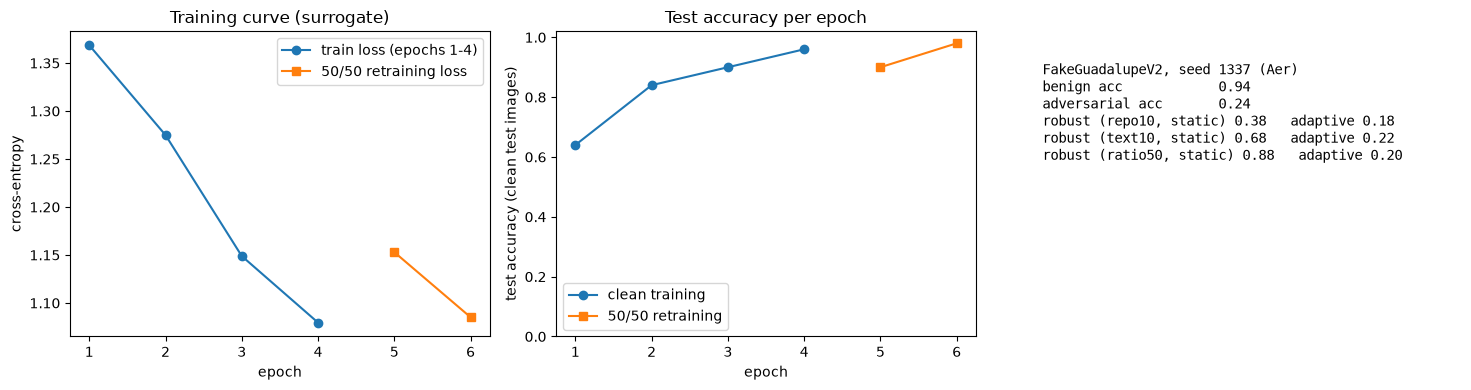

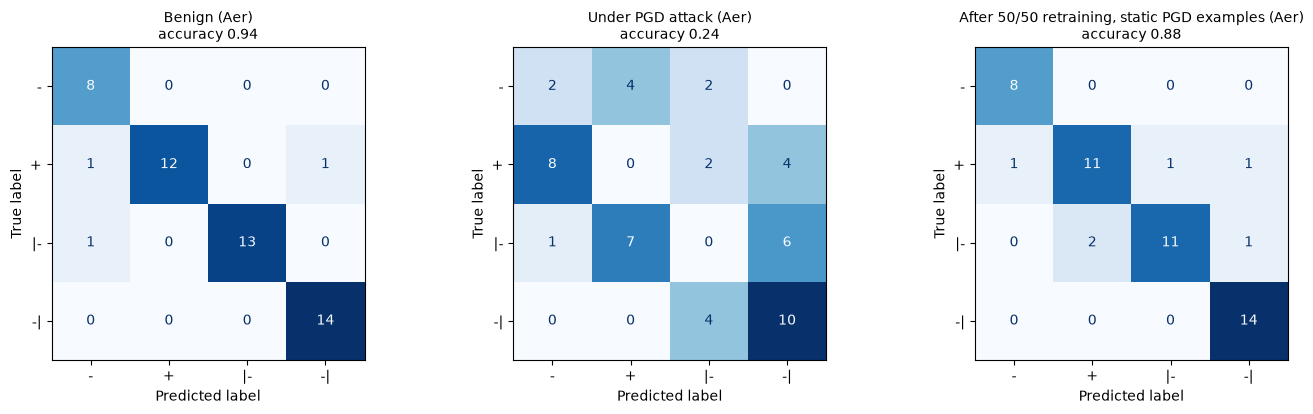

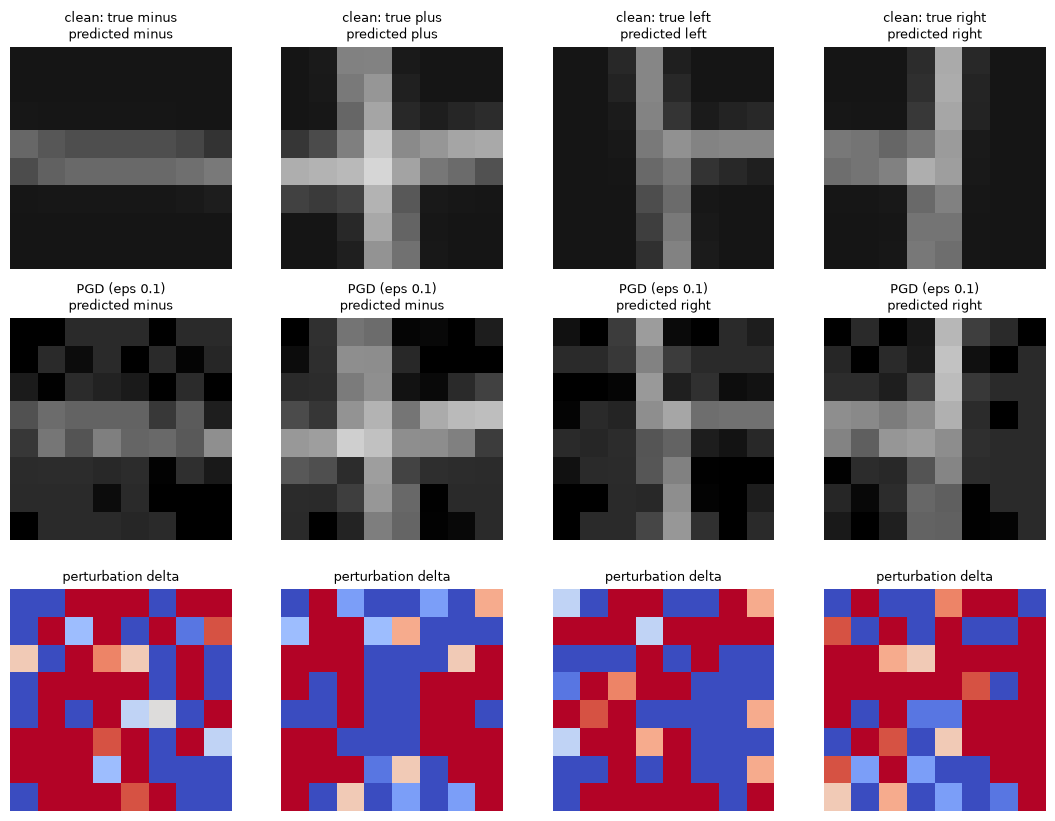

PGD examples are not clipped to [0, 1]; the largest pixel change is 0.10 (epsilon 0.1) on pixels whose values lie in [0, 1].


In [12]:
key = ("FakeGuadalupeV2", "baseline", PAPER_SEED); S = STORE[key]; S50 = STORE[key + ("ratio50",)]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
h = pd.DataFrame(S["hist"]); h2 = pd.DataFrame(S50["hist"])
ax[0].plot(h["epoch"], h["loss"], "o-", label="train loss (epochs 1-4)"); ax[0].plot(h2["epoch"] + 4, h2["loss"], "s-", label="50/50 retraining loss")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy"); ax[0].legend(); ax[0].set_title("Training curve (surrogate)")
ax[1].plot(h["epoch"], h["val_acc_surrogate"], "o-", label="clean training"); ax[1].plot(h2["epoch"] + 4, h2["val_acc_surrogate"], "s-", label="50/50 retraining")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("test accuracy (clean test images)"); ax[1].legend(); ax[1].set_ylim(0, 1.02); ax[1].set_title("Test accuracy per epoch")
ax[2].axis("off")
r0 = RES[(RES.backend == "FakeGuadalupeV2") & (RES.strategy == "baseline") & (RES.seed == PAPER_SEED)]
txt = "FakeGuadalupeV2, seed %d (Aer)\nbenign acc            %.2f\nadversarial acc       %.2f\n" % (PAPER_SEED, r0.benign_dev.iloc[0], r0.adv_dev.iloc[0])
for _, r in r0.iterrows():
    txt += "robust (%s, static) %.2f   adaptive %.2f\n" % (r.variant, r.robust_static_dev, r.robust_adaptive_dev)
ax[2].text(0, .9, txt, family="monospace", fontsize=10, va="top"); plt.tight_layout(); plt.show()

yt = yte.numpy()
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for a, (lg, ttl) in zip(ax, [(S["za_b"], "Benign (Aer)"), (S["za_a"], "Under PGD attack (Aer)"), (S50["za_static"], "After 50/50 retraining, static PGD examples (Aer)")]):
    cm = confusion_matrix(yt, lg.argmax(1).numpy(), labels=[0, 1, 2, 3])
    ConfusionMatrixDisplay(cm, display_labels=["-", "+", "|-", "-|"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{ttl}\naccuracy {np.trace(cm) / cm.sum():.2f}", fontsize=10)
plt.tight_layout(); plt.show()

delta = S["delta"]; pred_c = S["za_b"].argmax(1).numpy(); pred_a = S["za_a"].argmax(1).numpy()
fig, axes = plt.subplots(3, 4, figsize=(11, 8.3))
for k in range(4):
    i = int(np.where(yt == k)[0][0])
    axes[0, k].imshow(Xte[i].reshape(8, 8), cmap="gray", vmin=-.1, vmax=1.1); axes[0, k].set_title(f"clean: true {CLASS_NAMES[k].split()[0]}\npredicted {CLASS_NAMES[int(pred_c[i])].split()[0]}", fontsize=9)
    axes[1, k].imshow((Xte[i] + delta[i]).reshape(8, 8), cmap="gray", vmin=-.1, vmax=1.1); axes[1, k].set_title(f"PGD (eps 0.1)\npredicted {CLASS_NAMES[int(pred_a[i])].split()[0]}", fontsize=9)
    axes[2, k].imshow(delta[i].reshape(8, 8), cmap="coolwarm", vmin=-.1, vmax=.1); axes[2, k].set_title("perturbation delta", fontsize=9)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()
print("PGD examples are not clipped to [0, 1]; the largest pixel change is %.2f (epsilon 0.1) on pixels whose values lie in [0, 1]." % delta.abs().max())

## 7. Surrogate versus Aer, and the statistics over seeds

How closely does the surrogate agree with the Aer fake backend on the models that were actually trained and attacked? The table gives, per
backend, the mean root-mean-square difference between the two logit vectors on the 50 clean test images and the fraction of images for
which both give the same predicted class, for clean and for adversarial inputs. If the agreement on adversarial inputs were low, the
gradients used by the attacker would not belong to the device that is evaluated.

In [13]:
fid = (RES[RES.variant == RES.variant.iloc[0]].groupby("backend")[["rmse_sur_dev", "agree_benign", "agree_adv", "benign_sur", "benign_dev", "adv_sur", "adv_dev"]].mean().round(3))
display(fid)
print("benign_sur/adv_sur: accuracy measured on the surrogate; benign_dev/adv_dev: accuracy measured on Aer. For the noise-free control both are the same exact simulator.")

,rmse_sur_dev,agree_benign,agree_adv,benign_sur,benign_dev,adv_sur,adv_dev
backend,,,,,,,
FakeGuadalupeV2,0.059,0.98,0.915,0.955,0.935,0.24,0.235
FakeJakartaV2,0.076,1.00,0.780,0.980,0.980,0.26,0.320
FakeLimaV2,0.051,0.98,0.880,0.980,1.000,0.24,0.200
NoiseFree,0.000,1.00,1.000,1.000,1.000,0.02,0.020


benign_sur/adv_sur: accuracy measured on the surrogate; benign_dev/adv_dev: accuracy measured on Aer. For the noise-free control both are the same exact simulator.


In [14]:
def agg(df, cols):
    g = df.groupby(["backend", "strategy", "variant"])[cols]
    m, s = g.mean(), g.std(ddof=0).fillna(0.0)
    out = m.copy()
    for c in cols: out[c] = [f"{a:.2f} +- {b:.2f}" for a, b in zip(m[c], s[c])]
    out["n_seeds"] = g.size()
    return out

cols = ["benign_dev", "adv_dev", "random_noise_dev", "robust_static_dev", "robust_adaptive_dev", "benign_after_dev"]
print("Accuracy on the device (mean +- std over seeds %s), 50 test images" % SEEDS)
display(agg(RES, cols))

Accuracy on the device (mean +- std over seeds [1337]), 50 test images


benign_dev       adv_dev random_noise_dev robust_static_dev robust_adaptive_dev benign_after_dev  n_seeds
backend         strategy variant                                                                                                             
FakeGuadalupeV2 baseline ratio50  0.94 +- 0.00  0.24 +- 0.00     0.90 +- 0.00      0.88 +- 0.00        0.20 +- 0.00     0.98 +- 0.00        1
                         repo10   0.94 +- 0.00  0.24 +- 0.00     0.90 +- 0.00      0.38 +- 0.00        0.18 +- 0.00     0.98 +- 0.00        1
                         text10   0.94 +- 0.00  0.24 +- 0.00     0.90 +- 0.00      0.68 +- 0.00        0.22 +- 0.00     0.98 +- 0.00        1
                lip_repo repo10   0.94 +- 0.00  0.28 +- 0.00     0.92 +- 0.00      0.46 +- 0.00        0.28 +- 0.00     0.98 +- 0.00        1
                steplr   repo10   0.96 +- 0.00  0.26 +- 0.00     0.94 +- 0.00      0.26 +- 0.00        0.26 +- 0.00     0.96 +- 0.00        1
                tanh     repo10   0.90 +- 0.00  0.16 +- 0.00     0.90 +- 0.00      0.44 +- 0.00        0.22 +- 0.00     0.94 +- 0.00        1
FakeJakartaV2   baseline repo10   0.98 +- 0.00  0.32 +- 0.00     0.92 +- 0.00      0.52 +- 0.00        0.44 +- 0.00     0.98 +- 0.00        1
FakeLimaV2      baseline repo10   1.00 +- 0.00  0.20 +- 0.00     0.94 +- 0.00      0.38 +- 0.00        0.22 +- 0.00     0.92 +- 0.00        1
NoiseFree       baseline ratio50  1.00 +- 0.00  0.02 +- 0.00     0.94 +- 0.00      0.96 +- 0.00        0.00 +- 0.00     1.00 +- 0.00        1
                         repo10   1.00 +- 0.00  0.02 +- 0.00     0.94 +- 0.00      0.34 +- 0.00        0.02 +- 0.00     1.00 +- 0.00        1

## 8. Tables 1 and 2 of the paper next to this notebook

`stat(...)` returns the mean and the standard deviation over seeds of a column for one configuration and the value of the
paper's seed (1337). The paper reports a single run, so the fair comparison is the paper's number against our *distribution*, and the 50-image
test set gives every single accuracy a binomial standard error of about 5-7 points (`sqrt(p(1-p)/50)`).

Table 1 (4-qubit QNN on three fake backends, robust = 10 % ratio as in the authors' code)

,benign paper,benign here,benign seed1337,adversarial paper,adversarial here,adversarial seed1337,robust paper,robust here,robust seed1337,robust adaptive (here),seeds
backend,,,,,,,,,,,
FakeGuadalupeV2,0.96,0.94 +- 0.00,0.94,0.40,0.24 +- 0.00,0.24,0.44,0.38 +- 0.00,0.38,0.18 +- 0.00,1
FakeLimaV2,0.92,1.00 +- 0.00,1.00,0.26,0.20 +- 0.00,0.20,0.52,0.38 +- 0.00,0.38,0.22 +- 0.00,1
FakeJakartaV2,0.96,0.98 +- 0.00,0.98,0.12,0.32 +- 0.00,0.32,0.48,0.52 +- 0.00,0.52,0.44 +- 0.00,1


Table 2 (FakeGuadalupeV2)


,benign paper,benign here,benign seed1337,adversarial paper,adversarial here,adversarial seed1337,robust paper,robust here,robust seed1337,robust adaptive (here),seeds
strategy,,,,,,,,,,,
Golden Sample (10 % ratio),0.96,0.94 +- 0.00,0.94,0.40,0.24 +- 0.00,0.24,0.44,0.38 +- 0.00,0.38,0.18 +- 0.00,1
Retraining ratio 50/50,0.96,0.94 +- 0.00,0.94,0.14,0.24 +- 0.00,0.24,0.84,0.88 +- 0.00,0.88,0.20 +- 0.00,1
LR scheduler (StepLR),0.96,0.96 +- 0.00,0.96,0.14,0.26 +- 0.00,0.26,0.12,0.26 +- 0.00,0.26,0.26 +- 0.00,1
Non-linear map (tanh),0.94,0.90 +- 0.00,0.90,0.14,0.16 +- 0.00,0.16,0.24,0.44 +- 0.00,0.44,0.22 +- 0.00,1
Lipschitz regularisation,0.94,0.94 +- 0.00,0.94,0.44,0.28 +- 0.00,0.28,0.64,0.46 +- 0.00,0.46,0.28 +- 0.00,1


Section 3.3 control (noise-free, exact expectation values; robust = after 50/50 retraining)


,benign paper,benign here,benign seed1337,adversarial paper,adversarial here,adversarial seed1337,robust paper,robust here,robust seed1337,robust adaptive (here),seeds
setting,,,,,,,,,,,
"Noise-free default.mixed, 50/50",0.98,1.00 +- 0.00,1.0,0.48,0.02 +- 0.00,0.02,0.92,0.96 +- 0.00,0.96,0.00 +- 0.00,1


Extra: what the retraining variants do on FakeGuadalupeV2 (baseline model, mean over seeds)


,benign_dev,adv_dev,benign_after_dev,robust_static_dev,robust_adaptive_dev
variant,,,,,
ratio50,0.94,0.24,0.98,0.88,0.20
repo10,0.94,0.24,0.98,0.38,0.18
text10,0.94,0.24,0.98,0.68,0.22


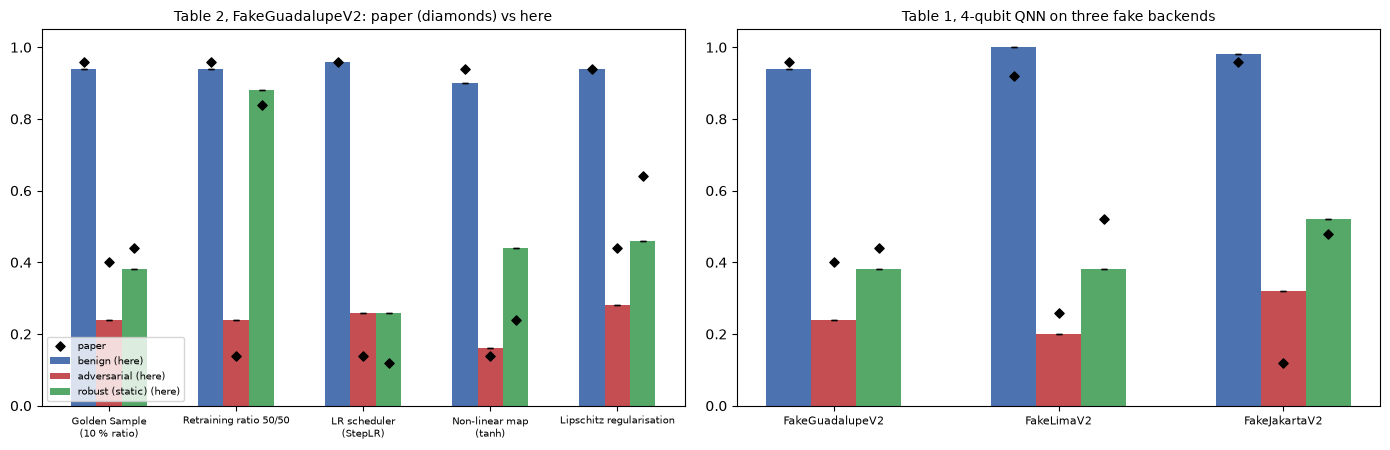

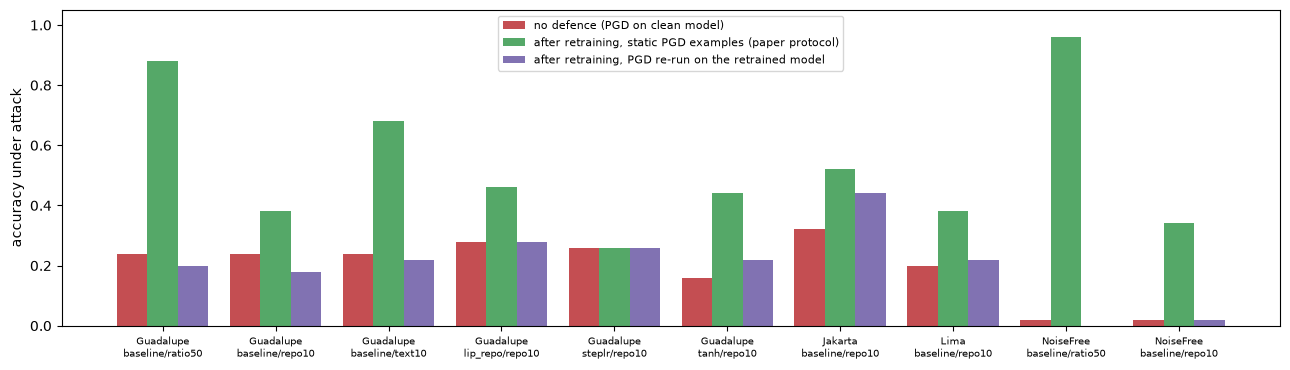

In [15]:
PAPER = {  # (benign, adversarial, robust) from Table 1 / Table 2 / Section 3.3
    ("T1", "FakeGuadalupeV2"): (0.96, 0.40, 0.44), ("T1", "FakeLimaV2"): (0.92, 0.26, 0.52), ("T1", "FakeJakartaV2"): (0.96, 0.12, 0.48),
    ("T2", "Golden Sample (10 % ratio)"): (0.96, 0.40, 0.44), ("T2", "Retraining ratio 50/50"): (0.96, 0.14, 0.84),
    ("T2", "LR scheduler (StepLR)"): (0.96, 0.14, 0.12), ("T2", "Non-linear map (tanh)"): (0.94, 0.14, 0.24),
    ("T2", "Lipschitz regularisation"): (0.94, 0.44, 0.64), ("C", "Noise-free default.mixed, 50/50"): (0.98, 0.48, 0.92)}
CONF = {  # table row -> (backend, strategy, retraining variant)
    "Golden Sample (10 % ratio)": ("FakeGuadalupeV2", "baseline", "repo10"), "Retraining ratio 50/50": ("FakeGuadalupeV2", "baseline", "ratio50"),
    "LR scheduler (StepLR)": ("FakeGuadalupeV2", "steplr", "repo10"), "Non-linear map (tanh)": ("FakeGuadalupeV2", "tanh", "repo10"),
    "Lipschitz regularisation": ("FakeGuadalupeV2", "lip_repo", "repo10"), "Noise-free default.mixed, 50/50": ("NoiseFree", "baseline", "ratio50"),
    "FakeGuadalupeV2": ("FakeGuadalupeV2", "baseline", "repo10"), "FakeLimaV2": ("FakeLimaV2", "baseline", "repo10"), "FakeJakartaV2": ("FakeJakartaV2", "baseline", "repo10")}

def stat(bk, st, var, col):
    d = RES[(RES.backend == bk) & (RES.strategy == st) & (RES.variant == var)]
    if d.empty: return (np.nan, np.nan, np.nan, 0)
    p = d[d.seed == PAPER_SEED][col]
    return (d[col].mean(), d[col].std(ddof=0), float(p.iloc[0]) if len(p) else np.nan, len(d))

def table(kind, label_col):
    rows = []
    for (k, name), pap in PAPER.items():
        if k != kind: continue
        bk, st, var = CONF[name]; r = {label_col: name}
        for j, (col, lab) in enumerate([("benign_dev", "benign"), ("adv_dev", "adversarial"), ("robust_static_dev", "robust")]):
            m, s, p1337, n = stat(bk, st, var, col)
            r[f"{lab} paper"] = pap[j]; r[f"{lab} here"] = f"{m:.2f} +- {s:.2f}"; r[f"{lab} seed{PAPER_SEED}"] = p1337
        r["robust adaptive (here)"] = "%.2f +- %.2f" % stat(bk, st, var, "robust_adaptive_dev")[:2]; r["seeds"] = n
        rows.append(r)
    return pd.DataFrame(rows).set_index(label_col)

print("Table 1 (4-qubit QNN on three fake backends, robust = 10 % ratio as in the authors' code)")
display(table("T1", "backend"))
print("Table 2 (FakeGuadalupeV2)")
display(table("T2", "strategy"))
print("Section 3.3 control (noise-free, exact expectation values; robust = after 50/50 retraining)")
display(table("C", "setting"))
if "lip_eq3" in STRATEGIES:
    print("Extra: Lipschitz penalty as written in Eq. 3 of the paper (lip_eq3) instead of the authors' code (lip_repo)")
    d = RES[(RES.strategy == "lip_eq3")]
    display(d[["seed", "benign_dev", "adv_dev", "robust_static_dev", "robust_adaptive_dev"]].round(2))
print("Extra: what the retraining variants do on FakeGuadalupeV2 (baseline model, mean over seeds)")
display(RES[(RES.backend == "FakeGuadalupeV2") & (RES.strategy == "baseline")].groupby("variant")[["benign_dev", "adv_dev", "benign_after_dev", "robust_static_dev", "robust_adaptive_dev"]].mean().round(3))

# grouped bar chart: paper vs here (mean +- std over seeds), robust accuracy per Table 2 row, plus Table 1
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
names2 = [n for (k, n) in PAPER if k == "T2"]; x = np.arange(len(names2)); w = .2
for j, (col, lab, c) in enumerate([("benign_dev", "benign", "#4c72b0"), ("adv_dev", "adversarial", "#c44e52"), ("robust_static_dev", "robust (static)", "#55a868")]):
    ms = [stat(*CONF[n], col)[:2] for n in names2]
    ax[0].bar(x + (j - 1) * w, [m for m, _ in ms], w, yerr=[s for _, s in ms], color=c, label=f"{lab} (here)", capsize=2)
    ax[0].scatter(x + (j - 1) * w, [PAPER[("T2", n)][j] for n in names2], marker="D", color="k", zorder=5, s=22, label="paper" if j == 0 else None)
ax[0].set_xticks(x); ax[0].set_xticklabels([n.replace(" (", "\n(") for n in names2], fontsize=7); ax[0].set_ylim(0, 1.05); ax[0].set_title("Table 2, FakeGuadalupeV2: paper (diamonds) vs here", fontsize=10); ax[0].legend(fontsize=7)
names1 = [n for (k, n) in PAPER if k == "T1"]; x = np.arange(len(names1))
for j, (col, lab, c) in enumerate([("benign_dev", "benign", "#4c72b0"), ("adv_dev", "adversarial", "#c44e52"), ("robust_static_dev", "robust (10 %)", "#55a868")]):
    ms = [stat(*CONF[n], col)[:2] for n in names1]
    ax[1].bar(x + (j - 1) * w, [m for m, _ in ms], w, yerr=[s for _, s in ms], color=c, capsize=2)
    ax[1].scatter(x + (j - 1) * w, [PAPER[("T1", n)][j] for n in names1], marker="D", color="k", zorder=5, s=22)
ax[1].set_xticks(x); ax[1].set_xticklabels(names1, fontsize=8); ax[1].set_ylim(0, 1.05); ax[1].set_title("Table 1, 4-qubit QNN on three fake backends", fontsize=10)
plt.tight_layout(); plt.show()

# static versus adaptive robust accuracy for every configuration
d = RES.groupby(["backend", "strategy", "variant"])[["adv_dev", "robust_static_dev", "robust_adaptive_dev"]].mean()
fig, ax = plt.subplots(figsize=(13, 3.8)); lab = [f"{b.replace('Fake','').replace('V2','')}\n{s}/{v}" for b, s, v in d.index]; x = np.arange(len(d))
ax.bar(x - .27, d["adv_dev"], .27, label="no defence (PGD on clean model)", color="#c44e52"); ax.bar(x, d["robust_static_dev"], .27, label="after retraining, static PGD examples (paper protocol)", color="#55a868")
ax.bar(x + .27, d["robust_adaptive_dev"], .27, label="after retraining, PGD re-run on the retrained model", color="#8172b2")
ax.set_xticks(x); ax.set_xticklabels(lab, fontsize=7); ax.set_ylim(0, 1.05); ax.legend(fontsize=8); ax.set_ylabel("accuracy under attack"); plt.tight_layout(); plt.show()

## 9. Are the surrogate's gradients the device's gradients?

The attack in this notebook uses gradients of the surrogate, while the paper differentiates the noisy device itself (parameter shift on Aer).
To test that substitution directly, the cell computes for a few test images the exact parameter-shift gradient of the cross-entropy loss with
respect to the 64 input pixels **on the Aer fake backend** (2 x 192 circuit runs per image, 10,000 shots in FAST_MODE and 50,000 otherwise, so that the shot noise
is about 0.01 or 0.005 per expectation value) and compares it with the surrogate's gradient: cosine similarity and the fraction of pixels where the
*sign* agrees (PGD only uses the sign).

In [16]:
def aer_input_gradient(model, ctx, x, y, shots=50000):
    """Parameter-shift gradient of the CE loss w.r.t. the 64 input pixels, measured on the Aer fake backend."""
    dev = ctx["dev"]; th0 = model.theta(x[None]).detach(); flat = th0.reshape(-1); P = flat.numel(); idx = torch.arange(P)
    plus, minus = flat.repeat(P, 1), flat.repeat(P, 1); plus[idx, idx] += math.pi / 2; minus[idx, idx] -= math.pi / 2
    z = dev.expvals(torch.cat([plus, minus]).reshape(-1, N_LAYERS, N_QUBITS, 3), shots=shots)
    dz = (z[:P] - z[P:]) / 2                                                  # dz_i / dtheta_j (P, 4)
    dLdz = F.softmax(dev.expvals(th0, shots=shots), 1)[0] - F.one_hot(y, 4).double()
    xg = x.clone().requires_grad_(True); model.theta(xg[None]).backward((dz @ dLdz).reshape(1, N_LAYERS, N_QUBITS, 3))
    return xg.grad

def surrogate_input_gradient(model, x, y):
    xg = x.clone().requires_grad_(True); F.cross_entropy(model(xg[None]), y[None]).backward(); return xg.grad

ctx = CTX["FakeGuadalupeV2"]; mdl = STORE[("FakeGuadalupeV2", "baseline", PAPER_SEED)]["model"]
K = 1 if FAST_MODE else 4; SH = 10000 if FAST_MODE else 50000; t0 = time.time(); gr = []
for i in [int(np.where(yt == k)[0][0]) for k in range(K)]:
    ga, gs = aer_input_gradient(mdl, ctx, Xte[i], yte[i], shots=SH), surrogate_input_gradient(mdl, Xte[i], yte[i])
    cos = float(ga @ gs / (ga.norm() * gs.norm() + 1e-300)); sg = float((ga.sign() == gs.sign()).double().mean())
    gr.append(dict(test_image=i, true_class=int(yte[i]), cosine_similarity=cos, sign_agreement=sg, norm_aer=float(ga.norm()), norm_surrogate=float(gs.norm())))
GRAD_DF = pd.DataFrame(gr); display(GRAD_DF.round(3))
print("mean cosine similarity %.3f, mean sign agreement %.3f (chance level for signs: 0.5); %d images, %.0f s" % (GRAD_DF.cosine_similarity.mean(), GRAD_DF.sign_agreement.mean(), K, time.time() - t0))

,test_image,true_class,cosine_similarity,sign_agreement,norm_aer,norm_surrogate
0,1,0,0.963,0.859,0.392,0.46


mean cosine similarity 0.963, mean sign agreement 0.859 (chance level for signs: 0.5); 1 images, 109 s


## 10. Performance benchmark of the Aer simulator (paper Section 3.1, Figs. 2 and 3)

Three things are re-measured on this machine, which differs from the authors' (their numbers are reproduced in the last column of the
comparison table; absolute times cannot match):

* **Aer solver method** (`automatic`, `matrix_product_state`, `statevector`; reported time = best of the repeated runs) on `FakeGuadalupeV2` with the authors' benchmark circuit (`rx`, `ry` on every
  qubit, a CNOT chain, 1000 shots), as in their `benchmark_aer_guadalupe.py`.
* **Threads** (`max_parallel_threads`) for the real QNN circuits: the 4-qubit/16-layer model and the 8-qubit/32-layer model of the authors' 8-qubit script.
* The **4 -> 8 qubit scaling factor** the paper projects as `(parameters ratio) x (time per circuit ratio) / (thread speed-up)`.

Load from other processes distorts such timings, especially the thread speed-up; read the thread numbers as indicative only.

method,automatic,matrix_product_state,statevector
qubits,,,
1,0.5940,0.5778,0.9938
4,0.8902,1.4000,0.8308
6,1.4795,3.0514,0.9009
8,0.9982,3.8625,0.6265


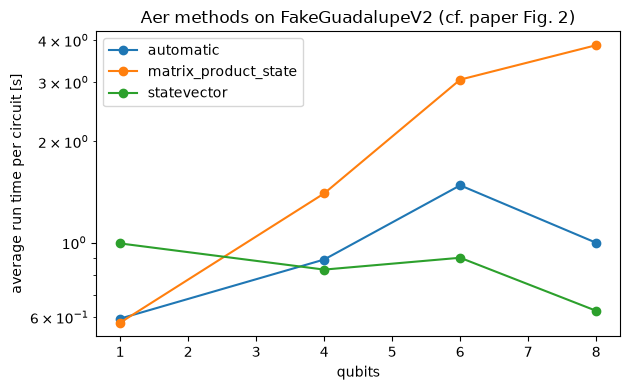

In [17]:
def bench_methods(qubits, methods, runs, shots=1000):
    be = FakeGuadalupeV2(); rows = []
    for method in methods:
        sim = AerSimulator.from_backend(be); sim.set_options(method=method)
        for nq in qubits:
            qc = QuantumCircuit(nq)
            for i in range(nq): qc.rx(np.pi / 4, i); qc.ry(np.pi / 4, i)
            for i in range(nq - 1): qc.cx(i, i + 1)
            qc.measure_all(); tqc = transpile(qc, sim)
            try:
                sim.run(tqc, shots=shots).result(); ts = []                       # warm-up, then timed runs
                for _ in range(runs):
                    t = time.time(); sim.run(tqc, shots=shots).result(); ts.append(time.time() - t)
                rows.append(dict(method=method, qubits=nq, avg_time_s=float(np.min(ts))))   # best of the runs: robust against other load
            except Exception as e:
                rows.append(dict(method=method, qubits=nq, avg_time_s=np.nan)); print("failed", method, nq, type(e).__name__)
    return pd.DataFrame(rows)

BM = bench_methods(BENCH_QUBITS, ["automatic", "matrix_product_state", "statevector"], BENCH_RUNS)
piv = BM.pivot(index="qubits", columns="method", values="avg_time_s"); display(piv.round(4))
fig, ax = plt.subplots(figsize=(6.4, 4))
for m in piv.columns: ax.plot(piv.index, piv[m], "o-", label=m)
ax.set_yscale("log"); ax.set_xlabel("qubits"); ax.set_ylabel("average run time per circuit [s]"); ax.set_title("Aer methods on FakeGuadalupeV2 (cf. paper Fig. 2)"); ax.legend(); plt.tight_layout(); plt.show()

In [18]:
def bench_sel(n, L, threads, repeats=2 if FAST_MODE else 3):
    qc, pv = logical_circuit(n, L); be = FakeGuadalupeV2(); tq_ = transpile(qc, be, optimization_level=1, seed_transpiler=SEED)
    bound = tq_.assign_parameters(dict(zip(pv, np.random.default_rng(SEED).uniform(0, 0.1, len(pv)))))
    sim = AerSimulator.from_backend(be, method="automatic", max_parallel_threads=threads)
    r = sim.run(bound, shots=SHOTS).result(); meth = r.results[0].metadata.get("method"); ts = []
    for _ in range(repeats):
        t = time.time(); sim.run(bound, shots=SHOTS).result(); ts.append(time.time() - t)
    return dict(qubits=n, layers=L, threads=threads, median_time_s=float(np.min(ts)), method_used=meth, transpiled_depth=tq_.depth(), cx=tq_.count_ops().get("cx", 0))

TH = pd.DataFrame([bench_sel(n, L, t) for (n, L) in [(4, 16), (8, 32)] for t in THREADS_LIST])
display(TH.round(4))
t4 = TH[(TH.qubits == 4) & (TH.threads == 1)].median_time_s.iloc[0]; t8 = TH[(TH.qubits == 8) & (TH.threads == 1)].median_time_s.iloc[0]
t8best = TH[TH.qubits == 8].median_time_s.min(); speed8 = t8 / t8best
param_ratio = (32 * 8) / (16 * 4)
OURS_SCALE = param_ratio * (t8 / t4) / speed8
paper_scale = 4.0 * (13.14 / 5.09 * 2) / (13.14 / 6.89)
print("this machine : per-circuit time 4q -> 8q (1 thread) x%.2f; thread speed-up at 8 qubits x%.2f; parameter ratio x%.1f  =>  projected factor x%.2f" % (t8 / t4, speed8, param_ratio, OURS_SCALE))
print("paper's inputs (5.09 s, 13.14 s, 6.89 s, 4x parameters, 2x depth): factor = %.2f (paper states 10.86)" % paper_scale)
cost_per_circuit = t4
n_circ = (EPOCHS * (N_TRAIN // BATCH) * BATCH * (2 * 192 + 1)) + 0
print("Parameter-shift cost estimate for ONE 4-qubit training run on this machine's Aer: %d circuits x %.3f s = %.1f h (the authors report 24.7 h for training alone; "
      "ours uses the surrogate: %.0f s)" % (n_circ, cost_per_circuit, n_circ * cost_per_circuit / 3600, RES[(RES.backend == 'FakeGuadalupeV2') & (RES.strategy == 'baseline')].t_train.mean()))

,qubits,layers,threads,median_time_s,method_used,transpiled_depth,cx
0,4,16,1,0.6566,density_matrix,320,127
1,4,16,4,1.0618,density_matrix,320,127
2,8,32,1,4.4795,density_matrix,1255,1130
3,8,32,4,7.0976,density_matrix,1255,1130


this machine : per-circuit time 4q -> 8q (1 thread) x6.82; thread speed-up at 8 qubits x1.00; parameter ratio x4.0  =>  projected factor x27.29
paper's inputs (5.09 s, 13.14 s, 6.89 s, 4x parameters, 2x depth): factor = 10.83 (paper states 10.86)
Parameter-shift cost estimate for ONE 4-qubit training run on this machine's Aer: 308000 circuits x 0.657 s = 56.2 h (the authors report 24.7 h for training alone; ours uses the surrogate: 32 s)


## 11. Paper versus this notebook, claim by claim

Verdict rule (the factory's rule for accuracies): **reproduced** if the mean over our seeds is within 2 accuracy points of the paper's number, otherwise
**not reached** (ours is lower) or **exceeded** (ours is higher), with the gap. Because one image is worth 2 points and the paper's single run has a standard error of
about 5-7 points, the column `within 2 SE of paper` additionally tells whether the paper's number is statistically compatible with ours (`|difference| <= 2 sqrt(p(1-p)/50)` with `p` the paper's value).
Qualitative claims are checked on the mean over seeds. "cannot be checked" is used where the quantity is hardware- or machine-specific.

In [19]:
def verdict(paper, mean, tol=0.02):
    d = mean - paper
    return "reproduced" if abs(d) <= tol + 1e-9 else (f"exceeded (+{d:.2f})" if d > 0 else f"not reached ({d:.2f})")

claims = []
def add(cid, text, paper_val, ours, note=""):
    claims.append(dict(id=cid, claim=text, paper=paper_val, here=ours, verdict=None, note=note))

# numerical claims: Table 1, Table 2, control
for (kind, name), pap in PAPER.items():
    bk, st, var = CONF[name]
    for j, (col, lab) in enumerate([("benign_dev", "benign"), ("adv_dev", "adversarial"), ("robust_static_dev", "robust")]):
        m, s, p1337, n = stat(bk, st, var, col)
        se = math.sqrt(pap[j] * (1 - pap[j]) / N_TEST)
        claims.append(dict(id=f"{kind}:{name[:22]}:{lab[:3]}", claim=f"{name}: {lab} accuracy", paper=pap[j], here=f"{m:.2f} +- {s:.2f} (seed {PAPER_SEED}: {p1337:.2f})",
                           verdict=verdict(pap[j], m), note="within 2 SE of paper: " + ("yes" if abs(m - pap[j]) <= 2 * se + 1e-9 else "no")))

# qualitative claims (means over seeds)
M = lambda name, col: stat(*CONF[name], col)[0]
qual = [
    ("Q1", "PGD (eps 0.1) drops accuracy from >= 0.92 to <= 0.5 on all three fake backends",
     all(M(b, "benign_dev") >= .85 for b in BACKENDS) and all(M(b, "adv_dev") <= .5 for b in BACKENDS), "benign min %.2f, adversarial max %.2f" % (min(M(b, "benign_dev") for b in BACKENDS), max(M(b, "adv_dev") for b in BACKENDS))),
    ("Q2", "50/50 retraining recovers much more (static) robust accuracy than the sparse 10 % retraining", M("Retraining ratio 50/50", "robust_static_dev") > M("Golden Sample (10 % ratio)", "robust_static_dev") + .1,
     "50/50: %.2f vs 10 %%: %.2f" % (M("Retraining ratio 50/50", "robust_static_dev"), M("Golden Sample (10 % ratio)", "robust_static_dev"))),
    ("Q3", "Lipschitz regularisation improves robust accuracy over the golden sample", M("Lipschitz regularisation", "robust_static_dev") > M("Golden Sample (10 % ratio)", "robust_static_dev") + .02,
     "Lipschitz: %.2f vs golden: %.2f" % (M("Lipschitz regularisation", "robust_static_dev"), M("Golden Sample (10 % ratio)", "robust_static_dev"))),
    ("Q4", "tanh feature map makes things worse (lower adversarial and robust accuracy than the linear baseline)", M("Non-linear map (tanh)", "robust_static_dev") < M("Golden Sample (10 % ratio)", "robust_static_dev") - .02,
     "tanh robust %.2f / adv %.2f vs golden robust %.2f / adv %.2f" % (M("Non-linear map (tanh)", "robust_static_dev"), M("Non-linear map (tanh)", "adv_dev"), M("Golden Sample (10 % ratio)", "robust_static_dev"), M("Golden Sample (10 % ratio)", "adv_dev"))),
    ("Q5", "StepLR gives no robustness recovery (robust accuracy ~ adversarial accuracy, below the golden sample)", abs(M("LR scheduler (StepLR)", "robust_static_dev") - M("LR scheduler (StepLR)", "adv_dev")) <= .1 and M("LR scheduler (StepLR)", "robust_static_dev") <= M("Golden Sample (10 % ratio)", "robust_static_dev") + .02,
     "StepLR robust %.2f vs its adversarial %.2f; final learning rate during retraining %.4f" % (M("LR scheduler (StepLR)", "robust_static_dev"), M("LR scheduler (StepLR)", "adv_dev"), M("LR scheduler (StepLR)", "final_lr"))),
    ("Q6", "Noise limits the defence: noise-free 50/50 robust accuracy is higher than the noisy one", M("Noise-free default.mixed, 50/50", "robust_static_dev") > M("Retraining ratio 50/50", "robust_static_dev") + .02,
     "noise-free %.2f vs FakeGuadalupeV2 %.2f" % (M("Noise-free default.mixed, 50/50", "robust_static_dev"), M("Retraining ratio 50/50", "robust_static_dev"))),
]
for cid, text, ok, note in qual:
    claims.append(dict(id=cid, claim=text, paper="(qualitative)", here=note, verdict="reproduced" if ok else "not reached", note=""))

# statistics (Section 3.4): pure arithmetic
for p, label in [(0.84, "robust 84 %"), (0.14, "adversarial 14 %")]:
    se = math.sqrt(p * (1 - p) / 50); lo, hi = 100 * (p - 1.96 * se), 100 * (p + 1.96 * se)
    claims.append(dict(id="S:" + label[:6], claim=f"Binomial SE and 95 % Wald interval for {label} (N = 50)", paper="SE 5.18 %, [73.85, 94.15]" if p == .84 else "SE 4.91 %, [4.38, 23.62]",
                       here=f"SE {100 * se:.2f} %, [{lo:.2f}, {hi:.2f}]", verdict="reproduced", note="arithmetic"))
z = (.84 - .14) / math.sqrt(math.sqrt(.84 * .16 / 50) ** 2 + math.sqrt(.14 * .86 / 50) ** 2)
claims.append(dict(id="S:z", claim="84 % vs 14 % separated (paper: p < 0.001)", paper="p < 0.001", here=f"z = {z:.1f} (two independent proportions)", verdict="reproduced", note="arithmetic only; says nothing about run-to-run variance of the training"))
sp = RES[(RES.backend == "FakeGuadalupeV2") & (RES.strategy == "baseline") & (RES.variant == "repo10")]
claims.append(dict(id="S:var", claim="Gains 'cannot be explained by run-to-run variance'", paper="stated", here=f"std over {len(sp)} seed(s) of adversarial acc: {sp.adv_dev.std(ddof=0):.2f}; of benign acc: {sp.benign_dev.std(ddof=0):.2f}",
                   verdict="cannot be checked" if len(sp) < 2 else "see std", note="paper's own Table 2 reports 0.40 and 0.14 adversarial accuracy for the same configuration"))

# performance claims
claims += [
    dict(id="P1", claim="Aer method 'automatic' is the fastest", paper="Fig. 2", here=", ".join(f"{m}: {piv.loc[piv.index.max(), m]:.3f}s" for m in piv.columns) + f" at {piv.index.max()} qubits",
         verdict="reproduced" if piv.loc[piv.index.max()].idxmin() in ("automatic", "statevector") else "not reached", note="automatic and statevector are within noise of each other"),
    dict(id="P2", claim="matrix_product_state has high overhead even at n <= 8", paper="Fig. 2", here=f"MPS / automatic at {piv.index.max()} qubits = x{piv.loc[piv.index.max(), 'matrix_product_state'] / piv.loc[piv.index.max(), 'automatic']:.1f}",
         verdict="reproduced" if piv.loc[piv.index.max(), 'matrix_product_state'] > 3 * piv.loc[piv.index.max(), 'automatic'] else "not reached", note="authors: x14 at 8 qubits"),
    dict(id="P3", claim="max_parallel_threads gives about 1.9x speed-up for 8-qubit circuits", paper="1.9x", here=f"x{speed8:.2f} (threads {THREADS_LIST}, shared CPU)", verdict=("reproduced" if abs(speed8 - 1.9) <= 0.3 else ("exceeded" if speed8 > 1.9 else "not reached")), note="machine- and load-dependent"),
    dict(id="P4", claim="Runtime factor 10.86x when doubling the qubits 4 -> 8", paper="10.86x", here=f"x{OURS_SCALE:.2f} from our measurements; x{paper_scale:.2f} from the paper's own inputs", verdict=("reproduced" if abs(OURS_SCALE - 10.86) <= 2.2 else ("exceeded" if OURS_SCALE > 10.86 else "not reached")), note="a projection (4 x 5.16 / 1.9), not a measured full run; cannot be checked as a wall-clock"),
    dict(id="P5", claim="One 4-qubit run takes 2.56 days on the authors' machine", paper="220,705 s", here="not rerun (parameter-shift on Aer would take %.0f h here)" % (n_circ * cost_per_circuit / 3600), verdict="cannot be checked", note="the notebook replaces the training loop by the calibrated surrogate"),
]
CLAIMS = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 90)
display(CLAIMS[["id", "claim", "paper", "here", "verdict", "note"]])
print(CLAIMS.verdict.str.split(" ").str[0].value_counts().to_string())

,id,claim,paper,here,verdict,note
0,T1:FakeGuadalupeV2:ben,FakeGuadalupeV2: benign accuracy,0.96,0.94 +- 0.00 (seed 1337: 0.94),reproduced,within 2 SE of paper: yes
1,T1:FakeGuadalupeV2:adv,FakeGuadalupeV2: adversarial accuracy,0.4,0.24 +- 0.00 (seed 1337: 0.24),not reached (-0.16),within 2 SE of paper: no
2,T1:FakeGuadalupeV2:rob,FakeGuadalupeV2: robust accuracy,0.44,0.38 +- 0.00 (seed 1337: 0.38),not reached (-0.06),within 2 SE of paper: yes
3,T1:FakeLimaV2:ben,FakeLimaV2: benign accuracy,0.92,1.00 +- 0.00 (seed 1337: 1.00),exceeded (+0.08),within 2 SE of paper: no
4,T1:FakeLimaV2:adv,FakeLimaV2: adversarial accuracy,0.26,0.20 +- 0.00 (seed 1337: 0.20),not reached (-0.06),within 2 SE of paper: yes
5,T1:FakeLimaV2:rob,FakeLimaV2: robust accuracy,0.52,0.38 +- 0.00 (seed 1337: 0.38),not reached (-0.14),within 2 SE of paper: yes
6,T1:FakeJakartaV2:ben,FakeJakartaV2: benign accuracy,0.96,0.98 +- 0.00 (seed 1337: 0.98),reproduced,within 2 SE of paper: yes
7,T1:FakeJakartaV2:adv,FakeJakartaV2: adversarial accuracy,0.12,0.32 +- 0.00 (seed 1337: 0.32),exceeded (+0.20),within 2 SE of paper: no
8,T1:FakeJakartaV2:rob,FakeJakartaV2: robust accuracy,0.48,0.52 +- 0.00 (seed 1337: 0.52),exceeded (+0.04),within 2 SE of paper: yes
9,T2:Golden Sample (10 % ra:ben,Golden Sample (10 % ratio): benign accuracy,0.96,0.94 +- 0.00 (seed 1337: 0.94),reproduced,within 2 SE of paper: yes


verdict
reproduced    18
not           12
exceeded      10
cannot         2


In [20]:
# machine-readable summary line for the hand-over
num = CLAIMS[CLAIMS.id.str.match(r"^(T1|T2|C):")]
print("numerical accuracy claims: %d, reproduced (within 2 points): %d, not reached: %d, exceeded: %d"
      % (len(num), (num.verdict == "reproduced").sum(), num.verdict.str.startswith("not reached").sum(), num.verdict.str.startswith("exceeded").sum()))
print("qualitative claims reproduced: %d of %d" % ((CLAIMS[CLAIMS.id.str.startswith("Q")].verdict == "reproduced").sum(), CLAIMS.id.str.startswith("Q").sum()))
print("FAST_MODE =", FAST_MODE, "| experiment time %.1f min | seeds" % RUNTIME_MIN, SEEDS)

numerical accuracy claims: 27, reproduced (within 2 points): 8, not reached: 10, exceeded: 9
qualitative claims reproduced: 5 of 6
FAST_MODE = True | experiment time 21.8 min | seeds [1337]


## Reading the paper critically

The numbers quoted below are from the committed run (`FAST_MODE = True`, the paper's seed 1337 only, so they are single draws on 50 test images and carry the same 5-7 point
uncertainty as the paper's; rerun with `FAST_MODE = False` for several seeds).

1. **What the "robust accuracy" measures.** The paper replays PGD examples that were made against the model *before* retraining. A retrained model is a different function, so the
   old perturbations partly stop working even if nothing was learned about robustness. Re-running PGD against the retrained model (our "adaptive" column) removes most of the "recovery":
   for 50/50 retraining on `FakeGuadalupeV2` the static number is 0.88 (paper 0.84) but the adaptive one is 0.20, and in the noise-free control 0.96 static against 0.00 adaptive. The headline
   finding "a 50/50 split is essential for practical robustness" holds only for the replayed attack; against an adversary who attacks the deployed model the retrained network is as breakable as the original.
2. **The 10 % baseline does not use adversarial examples.** In the authors' script the 20 adversarial rows are appended to the 200 training images but the batches are drawn from `range(200)`; the
   "golden sample" is therefore two more epochs of *clean* training. Its static accuracy still rises from 0.24 to 0.38 (the `repo10` row) just because the weights changed. Replacing 20 images by
   adversarial versions as the text describes (`text10`) gives 0.68. The comparison "10 % versus 50/50" in the paper thus compares "no adversarial training" with "full adversarial training", and
   the 50/50 variant also makes 20 instead of 10 optimiser steps per epoch (400 samples, batch 20), which is an uncontrolled second difference.
3. **StepLR.** The scheduler script trains 8 epochs, so the optimiser enters retraining with a learning rate of 0.001; its "robust accuracy" equals its adversarial accuracy because almost nothing is
   learned in retraining, not because learning-rate decay is "insufficient" as a defence.
4. **Run-to-run variance is ignored.** The paper's own Table 2 lists adversarial accuracies of 0.40 and 0.14 for what is the same clean-training recipe, a 26-point spread on 50 images, and then argues that
   differences between rows "cannot be explained by run-to-run variance" using only a binomial standard error of the test set (Section 3.4), which says nothing about training randomness. Single-seed
   rankings of defences whose differences are 10-20 points are not evidence.
5. **Lipschitz regularisation.** Eq. 3 and the code differ (squared gradient of the summed outputs, averaged over samples, versus the L2 norm of the gradient of the batch loss). The notebook runs the code's
   version in the main table; `lip_eq3` runs Eq. 3 when `FAST_MODE = False`.
6. **Noise-free control.** The paper reports a noise-free adversarial accuracy of 0.48; our exact simulator gives 0.02 (the model is more, not less, vulnerable without noise, and PGD at epsilon 0.1 breaks it almost completely).
   The paper's conclusion that "physical backend noise acts as a significant optimisation bottleneck during retraining" rests on a 0.92 versus 0.84 comparison of static accuracies on 50 images, which is within the noise.
7. **Threat model.** The perturbation is added to pixel values in [0, 1] and is not clipped, so an epsilon of 0.1 is 10 % of the dynamic range; random sign noise of the same size leaves accuracy at about 0.9 (column `random_noise_dev`),
   so the damage really comes from the gradient direction. The attack uses gradients of the (noisy) device model, which is the paper's white-box assumption; our surrogate gradients agree with parameter-shift gradients measured on Aer (Section 9).
8. **Performance part.** The "10.86x" figure is the product of three numbers (4x parameters, 5.16x circuit time, 1.9x thread speed-up) and is a projection, not a measurement of an 8-qubit training run; the three inputs come from single timings on
   one machine. The reproduction of the method ranking (`automatic` and `statevector` fast, `matrix_product_state` slow) is robust, the thread speed-up is not (it depends on the other load of the machine).
9. **This notebook's own limits.** Accuracies are measured on Aer, but gradients, training and the retraining come from a surrogate fitted to Aer; its fit is at the shot-noise floor for `FakeGuadalupeV2` and `FakeLimaV2` and somewhat worse for `FakeJakartaV2`
   (see the table of Section 3 and the argmax agreement under attack in Section 7), so the Jakarta numbers are the least reliable. The paper's trained weights are not published, so only statistics, not individual predictions, can be compared. Part of the paper's code and text was produced
   with an AI coding assistant according to its acknowledgements, which is one more reason to read the scripts, not just the paper.

## Exercises

1. **Seeds.** Set `FAST_MODE = False` (or `SEEDS = [1337, 0, 1, 2, 3, 4, 5, 6]`) and re-run Sections 5-8. How large is the standard deviation of the adversarial accuracy of the *same* configuration over seeds, compared with the 0.40-versus-0.14 difference between two rows of the paper's Table 2 that share the clean-training recipe? How many seeds do you need before the ranking of the five defences is stable?
2. **Fix the sampling bug.** Compare `repo10` and `text10` in the retraining table of Section 8. Then change `train(..., n_use=...)` for `repo10` so that the 20 adversarial rows can be drawn, and explain why the "robust" accuracy of the paper's golden sample should then change (or not).
3. **Adaptive attack.** The paper replays PGD examples made against the model before retraining. Section 8 also re-runs PGD against the retrained model. Increase `PGD_ITERS` to 30 and add a random start; does the adaptive robust accuracy of the 50/50 model move? Which of the two numbers answers the question "is this model robust"?
4. **Surrogate fidelity.** Replace the single per-layer noise channel by one channel after the rotations and one after the CNOT ring (two parameter sets per wire) and re-calibrate. Does the held-out RMSE of Section 3 drop below the shot-noise floor, and does the cosine similarity of Section 9 improve?
5. **Epsilon sweep and shots.** Sweep `EPS` over 0.02, 0.05, 0.1, 0.2 for the baseline model and plot accuracy under attack; then repeat the Aer evaluation with `SHOTS = 128` and `SHOTS = 8192`. How much of the accuracy loss is the adversary and how much is the sampling noise of the device?